# Project 2: Numerical Integration For Charged Particles


# 1. Importer

In [83]:
import numpy as np
import matplotlib.pyplot as plt

import scipy 
from scipy.integrate import solve_ivp

import time as pytime
from time import perf_counter
import time

from tqdm import tqdm

from functools import partial

from scipy.optimize import approx_fprime


# 2. Modellproblemer

In [85]:
# Felles modellproblemer (brukes av Boris, RK4 og FOSMM)

# 2D charged particle
# The static magnetic field
def B_2D(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])

# The vector potential
def A_2D(x):
    Ax = -x[1]*np.sqrt(x[0]**2 + x[1]**2)
    Ay = x[0]*np.sqrt(x[0]**2 + x[1]**2)
    Az = 0
    return 1/3 * np.array([Ax, Ay, Az])

# The electrostatic potential
def U_2D(x):
    return 1/(100*np.sqrt(x[0]**2 + x[1]**2))

# The gradient of the electrostatic potential
def grad_U_2D(x):
    Ux = x[0]/((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1]/((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100*np.array([Ux, Uy, Uz])

# Initial values
x0_2D = np.array([0.0, 1.0, 0.1])
v0_2D = np.array([0.09, 0.05, 0.20])


# Tokamak magnetic field
# The static magnetic field
def B_tokamak(x):
    Bx = -(2*x[1] + x[0]*x[2])/(2*(x[0]**2 + x[1]**2))
    By = (2*x[0] - x[1]*x[2])/(2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2) - 1)/(2*np.sqrt(x[0]**2 + x[1]**2))
    return np.array([Bx, By, Bz])

# The vector potential (arctan2, so it is correct also for x[0] < 0)
def A_tokamak(x):
    Ax = 0
    Ay = 1/2*(x[0] - np.log(np.sqrt(x[0]**2 + x[1]**2) + x[0]))
    Az = -1/2*(x[2]*np.arctan2(x[1], x[0]) + np.log(x[0]**2 + x[1]**2))
    return np.array([Ax, Ay, Az])

# The electrostatic potential
def U_tokamak(x):
    return 0

# The gradient of the electrostatic potential
def grad_U_tokamak(x):
    return 0

# Initial values
x0_tokamak = np.array([1.2, 0.0, 0.0])
v0_tokamak = np.array([0, 4.816e-4, -2.059e-3])

In [86]:
# Felles funksjoner

# Right-hand side of the ODE  x' = v,  v' = v x B(x) - grad U(x)
def ODEs(t, y, B, grad_U):
    x = y[:3]
    v = y[3:]

    dxdt = v
    dvdt = np.cross(v, B(x)) - grad_U(x)
    return np.concatenate((dxdt, dvdt))

# Energy  E = 1/2 |v|^2 + U(x).  x and v are either single vectors or arrays of shape (3, N)
def energy(x, v, U):
    return 0.5*(np.linalg.norm(v, ord=2, axis = 0))**2 + U(x)

# |E(t) - E(0)|, where E(0) is taken from the first column
def energy_change(x, v, U):
    return np.abs(energy(x, v, U) - energy(x[:,0], v[:,0], U))

# 3. Implementering av metodene

# Implementation of Boris method

In [87]:
def boris_method(ODEs, x0, v0, h_emilie, U, U_grad, B, bool_init,N_emilie):
    """
    General Boris method
    """
    # If the initial condition is the actual initial condition (want one step back)
    v_back = v0

    if bool_init: #if we are given (x0,v0) instead
        t_0 = 0
        t_back = t_0-(h_emilie/2)
        t_span_emilie = [t_0, t_back]

        initial_condition = np.concatenate((x0,v0))

        sol = solve_ivp(ODEs, t_span_emilie, initial_condition, args=(B, U_grad), first_step = (h_emilie/2), rtol=1e-10, atol=1e-12)
        v_back = sol.y[3:,-1] #???????????
    
    # The actual Boris method

    x_n = x0
    v_n_half = v_back
    
    x_array = np.zeros((3,N_emilie)) 
    v_array = np.zeros((3,N_emilie))

    start = time.perf_counter() # START MEASURING TIME

    for i in range(0,N_emilie):
        t = h_emilie/2*B(x_n)
        s = 2*t / (1 + np.dot(t, t))

        v_minus = v_n_half - (h_emilie/2)*U_grad(x_n)
        v_mark = v_minus + np.cross(v_minus, t)
        
        v_pluss = v_minus + np.cross(v_mark,s)

        v_n_pluss_half = v_pluss - (h_emilie/2)*U_grad(x_n)
        x_n_pluss_one = x_n + h_emilie*v_n_pluss_half

        # Update values:
        x_n = x_n_pluss_one
        v_n_half = v_n_pluss_half

        #put values into lists for plotting
        x_array[:,i] = x_n
        v_array[:,i] = v_n_half

    end = time.perf_counter() # STOP MEASURING TIME

    time_spent = end - start
        
    return x_array, v_array, time_spent

## Amanda (RK4)

### Classical Runge-Kutta 4 on the extended system

In [88]:
#ODEs (the right-hand side) is defined together with the model problems

#Defining the Runge Kutta 4 method

def RK4_amanda(y_n, h_amanda, B, grad_U):
    k_1 = h_amanda * ODEs(0, y_n, B, grad_U)
    k_2 = h_amanda * ODEs(0, y_n + 0.5*k_1, B, grad_U)
    k_3 = h_amanda * ODEs(0, y_n + 0.5*k_2, B, grad_U)
    k_4 = h_amanda * ODEs(0, y_n + k_3, B, grad_U)

    return y_n + (k_1 + 2*k_2 + 2*k_3 + k_4)/6




## Seline (FOSMM)

Implementation of Fourth-order symmetric multistep method:

In [89]:
def starting_values(y0, t_min, t_max, U_grad, B):
    t_vals = np.linspace(t_min, t_max, 8)
    solution = solve_ivp(ODEs,(t_min,t_max) , np.concatenate(y0), args=(B, U_grad), t_eval = t_vals, rtol=1e-12, atol=1e-14, method="DOP853") #y0 must be [x0, v0]
    return solution.y, solution.t

def v(x,j, h_seline):
    return delta(x, j)/h_seline

def delta(y, j):#five point central difference
    return 1/12*(y[:,j-2] - 8*y[:,j-1] + 8*y[:,j+1] - y[:,j+2])

def deltaA(A, x, j):#five point central difference
    return 1/12*(A(x[:,j-2]) - 8*A(x[:,j-1]) + 8*A(x[:,j+1]) - A(x[:,j+2]))

def F_j(A, v, U_grad, j, x, h_seline):
    A_jac = np.transpose(approx_fprime(x[:,j], A))

    A_delta = deltaA(A,x, j)/h_seline
    return A_jac@v(x,j,h_seline) - A_delta - U_grad(x[:,j])

def FOSMM_step(alpha, x , n, h_seline, A, v, U_grad, beta): #find x_(n+4)
    sum = 0
    for j in range(-4, 4):
        sum += alpha[4+j]*x[:,n+j]
    x[:,n+4] = 1/alpha[-1]*(h_seline**2*(beta[1]*F_j(A, v, U_grad,  n-1, x, h_seline) + beta[0]*F_j(A, v, U_grad, n, x, h_seline) + beta[1]*F_j(A, v, U_grad, n+1, x, h_seline))  - sum)

def t_j(t0, j, h_seline):
    return t0 + j*h_seline

def FOSMM(alpha, h_seline, A, U_grad,B, beta, T_max, y0): #y0 = [x0, v0]
    N_seline = int(T_max/h_seline) + 1 #number of steps
    start_vals = starting_values(y0, 0, 7*h_seline, U_grad, B) #0 til 7 riktig??
    x_start = start_vals[0][:3, :] #from t= 0 to 7
    v_start = start_vals[0][3:, :]

    x_arr = np.zeros((3,N_seline+2))
    v_arr = np.zeros((3,N_seline))

    x_arr[:, :8] = x_start    
    v_arr[:, :8] = v_start

    start = perf_counter()
    for n in range(8, N_seline+2): #evaluate two extra steps in order to find the last value of v

        FOSMM_step(alpha, x_arr, n-4, h_seline, A, v, U_grad, beta)
        v_arr[:,n-2] = v(x_arr, n-2, h_seline)

    stop = perf_counter()
    return x_arr[:, :N_seline], v_arr, stop - start


h_seline = 0.1
a = [-0.7, 0.1, 0.9]
beta = [1/3*(20*a[0]*a[1]*a[2]-4*(a[0]*a[1]+a[0]*a[2] + a[1]*a[2])-28*(a[0] + a[1] + a[2])-52), 1/3*(2*a[0]*a[1]*a[2] + 14*(a[0]*a[1] + a[0]*a[2] + a[1]*a[2]) + 26*(a[0]+a[1]+a[2]) + 38)]
alpha = [1, -7/5, 9/25, 22/125, -34/125, 22/125, 9/25, -7/5, 1]
T_max = 1e5

# 4. Task A: Kjøring og baneplott

#### INITIALIZING ARRAYS FOR BORIS

In [90]:
# INITITLISING BORIS:

N_emilie = int(10**5/ 0.1)

x_array_boris, v_array_boris, _ = boris_method(ODEs, x0_2D, v0_2D, 0.1,U_2D, grad_U_2D, B_2D, True, N_emilie)

x_array_boris_toko, v_array_boris_toko, _ = boris_method(ODEs, x0_tokamak, v0_tokamak, 0.1,U_tokamak, grad_U_tokamak, B_tokamak, True, N_emilie)

R_boris = np.sqrt(x_array_boris_toko[0]**2 + x_array_boris_toko[1]**2)

z = x_array_boris_toko[2]
;

''

#### INITIALIZING ARRAYS FOR RK4 2D particle

In [91]:
# Parameters
T_amanda = 1e5
h_amanda = 0.1
n_steps = int(T_amanda/h_amanda)
time_amanda = np.linspace(0, T_amanda, n_steps + 1)

# Preallocating arrays
y_arr_2D = np.zeros((n_steps + 1, 6))

# Initial condition: position + velocity
y_arr_2D[0] = np.concatenate((np.asarray(x0_2D), np.asarray(v0_2D)))

y_n = np.concatenate((x0_2D, v0_2D))

for i in tqdm(range(n_steps)):
    y_n = RK4_amanda(y_n, h_amanda, B_2D, grad_U_2D)
    y_arr_2D[i+1] = np.asarray(y_n)

# Extracting position and velocity
x_arr_2D = y_arr_2D[:, :3]
v_arr_2D = y_arr_2D[:, 3:]
    
       

100%|██████████| 1000000/1000000 [01:07<00:00, 14746.68it/s]


#### INITIALIZING ARRAYS FOR RK4 TOKAMAK MAGNETIC FIELD

In [92]:
# Parameters
T_amanda = 1e5
h_amanda = 0.1
n_steps = int(T_amanda/h_amanda)
time_amanda = np.linspace(0, T_amanda, n_steps + 1)

# Preallocating array
y_arr_tokamak = np.zeros((n_steps + 1, 6))

# Initial condition: position + velocity
y_arr_tokamak[0] = np.concatenate((
    np.asarray(x0_tokamak), np.asarray(v0_tokamak)))

y_n = np.concatenate((x0_tokamak, v0_tokamak))

for i in tqdm(range(n_steps)):
    y_n = RK4_amanda(y_n, h_amanda, B_tokamak, grad_U_tokamak)
    y_arr_tokamak[i+1] = np.asarray(y_n)

# Extracting position and velocity
x_arr_tokamak = y_arr_tokamak[:, :3]
v_arr_tokamak = y_arr_tokamak[:, 3:]

100%|██████████| 1000000/1000000 [01:09<00:00, 14395.63it/s]


In [93]:
#Plotting the trajectories of the two first coordinates of the solutions
# Cylindrical radial coordinate
R = np.sqrt(x_arr_tokamak[:, 0]**2 + x_arr_tokamak[:, 1]**2)
x3_amanda = x_arr_tokamak[:, 2]

#### INITIALIZING ARRAYS FOR FOSMM

In [94]:


y01 = np.array([x0_2D, v0_2D])

x1_seline, v1, _ = FOSMM(alpha, h_seline, A_2D, grad_U_2D, B_2D, beta, T_max, y01)

y02 = np.array([x0_tokamak, v0_tokamak])

x2_seline, v2 , _= FOSMM(alpha, h_seline, A_tokamak, grad_U_tokamak, B_tokamak, beta, T_max, y02)

Task A on model 3.1 with Fourth-order symmetric multistep method:

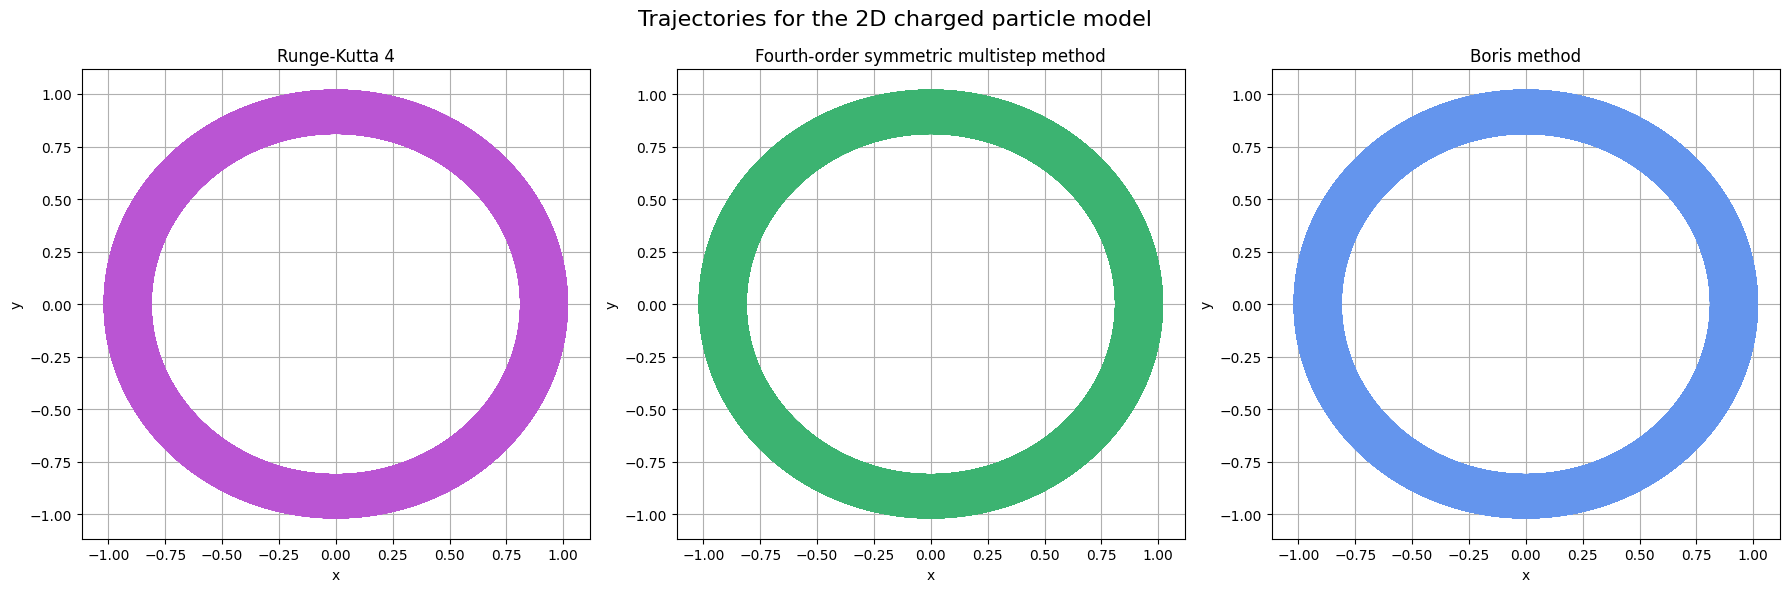

In [95]:
#Alle 2D-plott ved siden av hverandre
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Trajectories for the 2D charged particle model", fontsize=16)

#RK4
axes[0].plot(x_arr_2D[:, 0], x_arr_2D[:, 1], color='mediumorchid', label='x1')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Runge-Kutta 4')
axes[0].grid(True)

#FOSMM
axes[1].plot(x1_seline[0, :], x1_seline[1, :], color="mediumseagreen")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_array_boris[0], x_array_boris[1], label="trajectory", color="cornflowerblue")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].set_title("Boris method")
axes[2].grid(True)

plt.tight_layout()
plt.show()

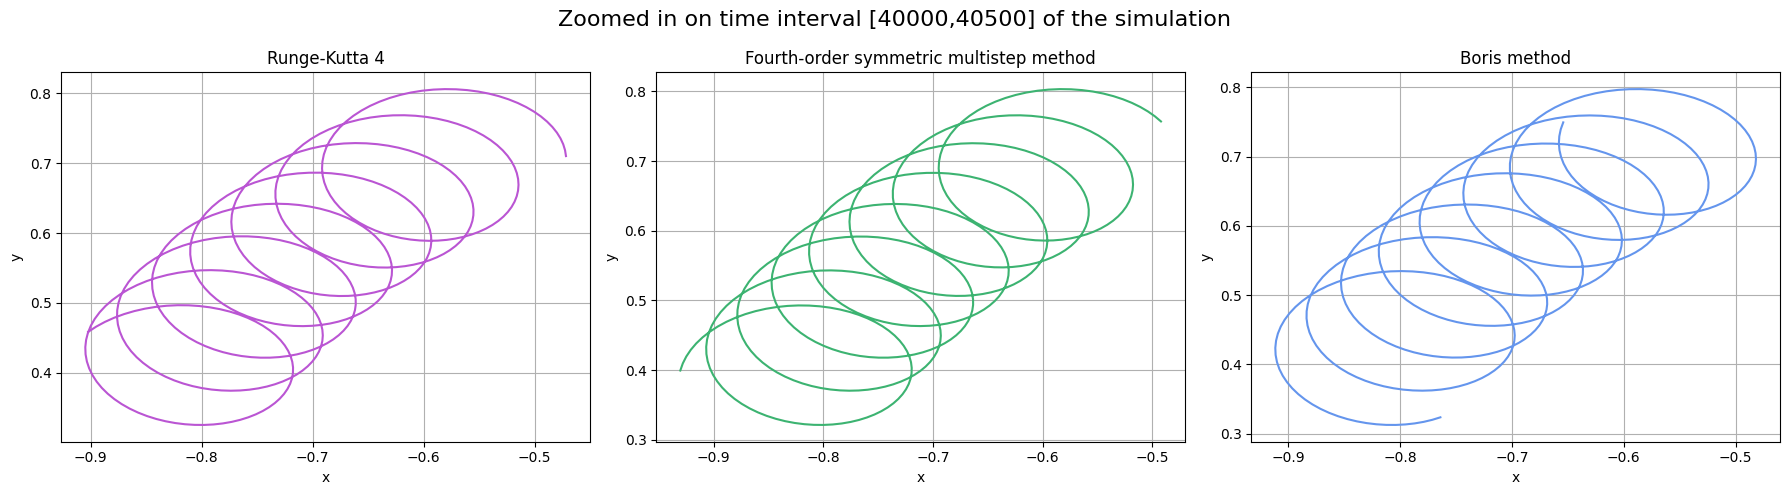

In [96]:
# ZOOMED-IN PLOTS OVER A SHORT TIME INTERVAL
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(x_arr_2D[:, 0][40000:40500], x_arr_2D[:, 1][40000:40500], color='mediumorchid', label='x1')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Runge-Kutta 4')
axes[0].grid(True)

#FOSMM
axes[1].plot(x1_seline[0, :][40000:40500], x1_seline[1, :][40000:40500], color="mediumseagreen")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_array_boris[0][40000:40500], x_array_boris[1][40000:40500], label="trajectory", color="cornflowerblue")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].set_title("Boris method")
axes[2].grid(True)

for ax in axes:
    ax.grid(True)

fig.suptitle("Zoomed in on time interval [40000,40500] of the simulation", fontsize=16)
plt.tight_layout()
plt.show()

we observe a "phase difference"

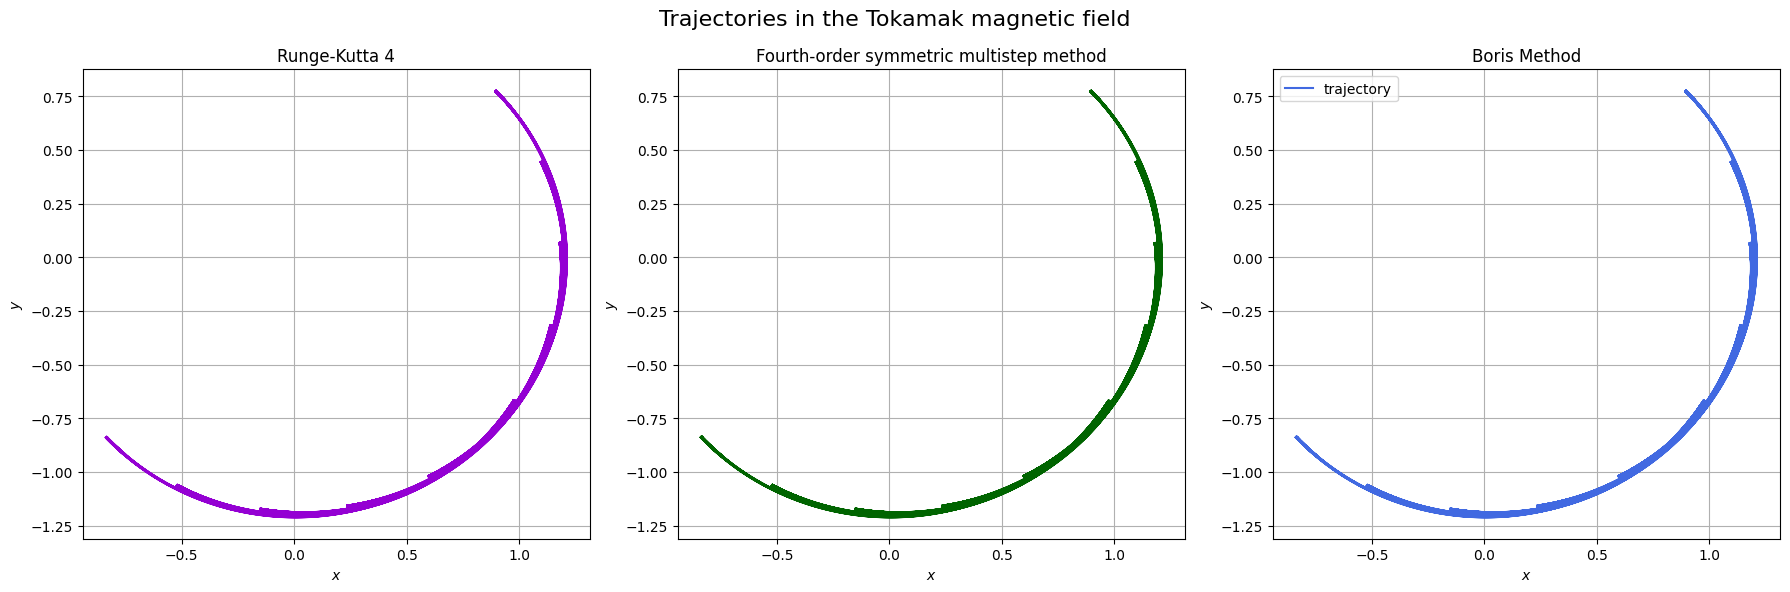

In [97]:
#Alle Tokamak-baner (x1-x2-planet) ved siden av hverandre
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(x_arr_tokamak[:, 0], x_arr_tokamak[:, 1], color="darkviolet")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$y$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(x2_seline[0, :], x2_seline[1, :], color="darkgreen")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$y$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_array_boris_toko[0], x_array_boris_toko[1], label="trajectory", color="royalblue")
axes[2].set_xlabel(r"$x$")
axes[2].set_ylabel(r"$y$")
axes[2].set_title("Boris Method")
axes[2].legend()
axes[2].grid(True)

fig.suptitle("Trajectories in the Tokamak magnetic field", fontsize=16)
plt.tight_layout()
plt.show()


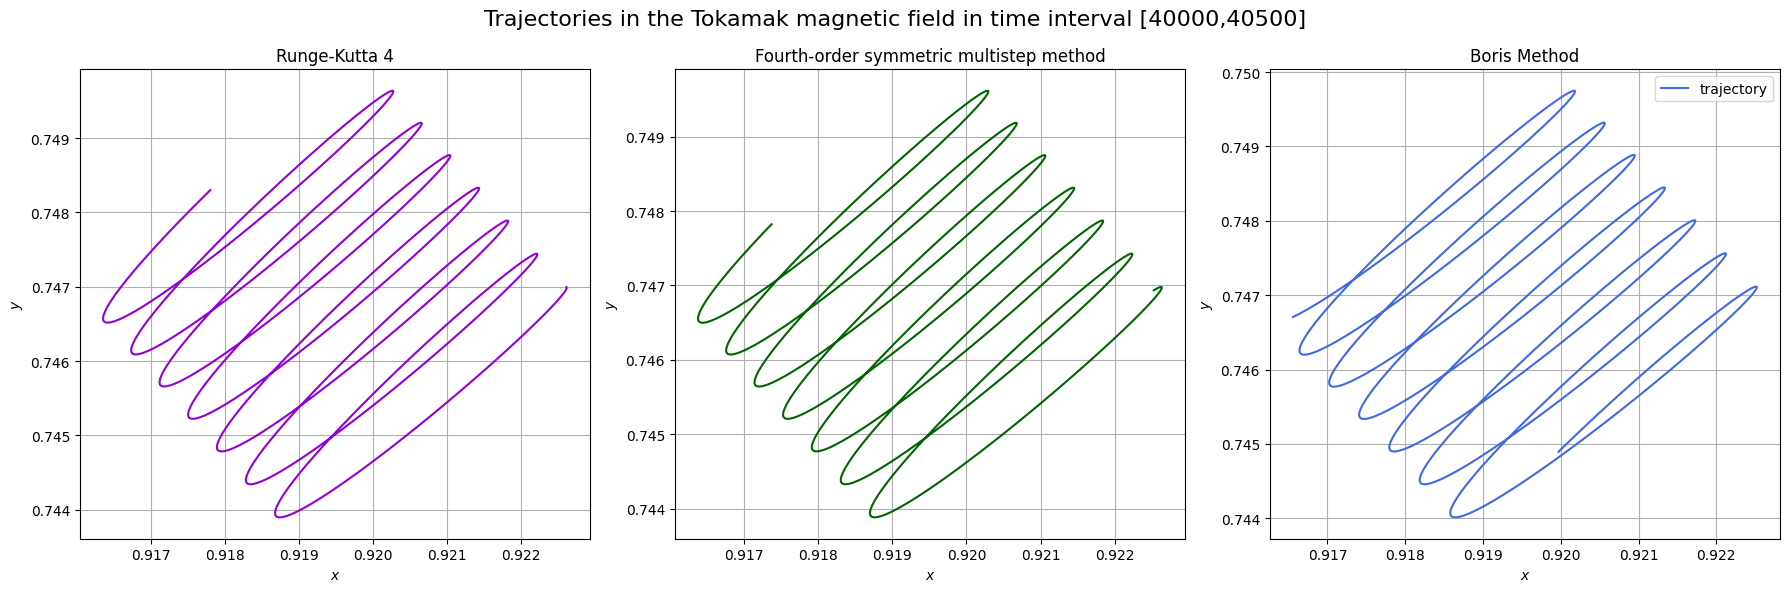

In [98]:
#Zoom in on smaller time interval
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(x_arr_tokamak[:, 0][40000:40500], x_arr_tokamak[:, 1][40000:40500], color="darkviolet")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$y$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(x2_seline[0, :][40000:40500], x2_seline[1, :][40000:40500], color="darkgreen")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$y$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_array_boris_toko[0][40000:40500], x_array_boris_toko[1][40000:40500], label="trajectory", color="royalblue")
axes[2].set_xlabel(r"$x$")
axes[2].set_ylabel(r"$y$")
axes[2].set_title("Boris Method")
axes[2].legend()
axes[2].grid(True)

fig.suptitle("Trajectories in the Tokamak magnetic field in time interval [40000,40500]", fontsize=16)
plt.tight_layout()
plt.show()


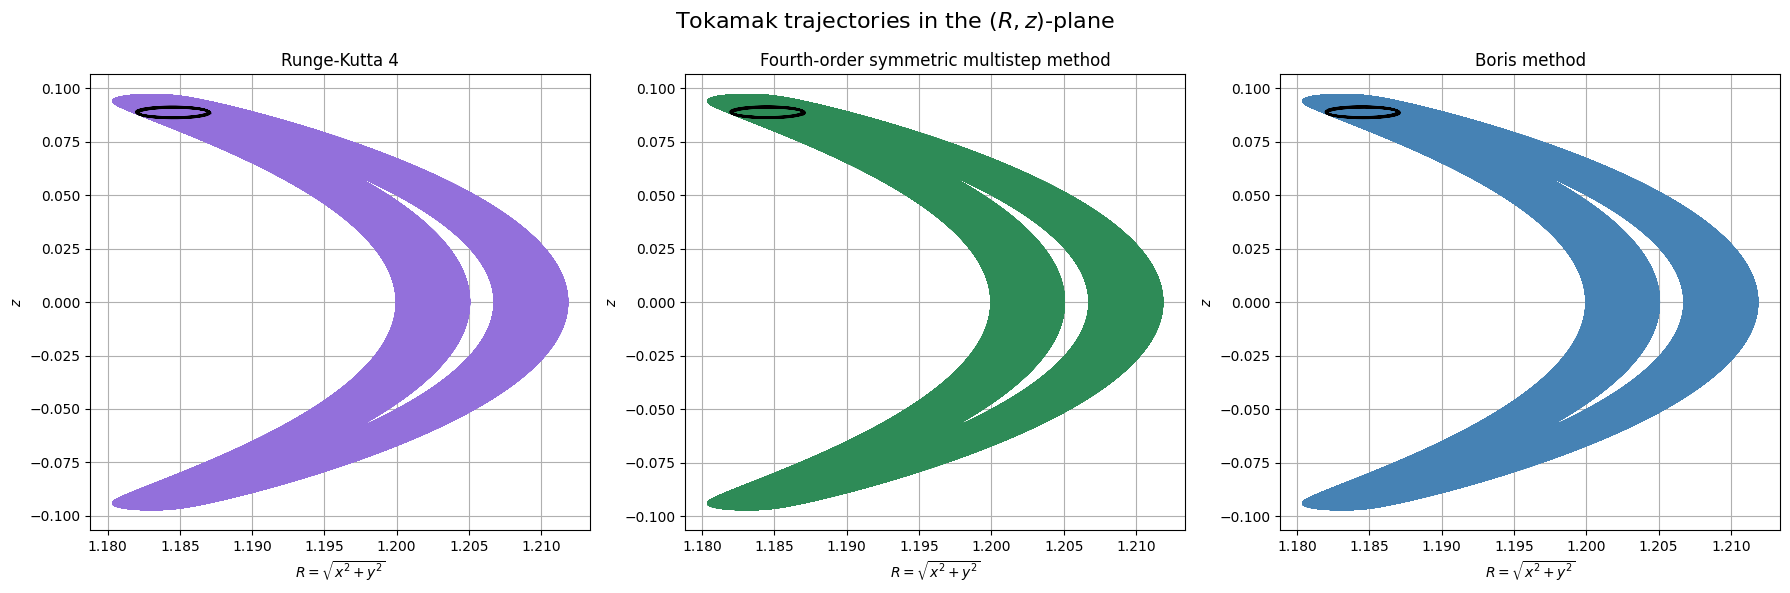

In [99]:
#Alle Tokamak-baner i R-x3-planet ved siden av hverandre
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(R, x3_amanda, color="mediumpurple")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x2_seline[0, :]**2 + x2_seline[1, :]**2), x2_seline[2, :], color="seagreen")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris, z, color="steelblue")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


axes[0].plot(R[40000:40500], x3_amanda[40000:40500], color="black")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x2_seline[0, :]**2 + x2_seline[1, :]**2)[40000:40500], x2_seline[2, :][40000:40500], color="black")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris[40000:40500], z[40000:40500], color="black")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


fig.suptitle("Tokamak trajectories in the $(R, z)$-plane", fontsize=16)
plt.tight_layout()
plt.show()


we zoom in on the black part:

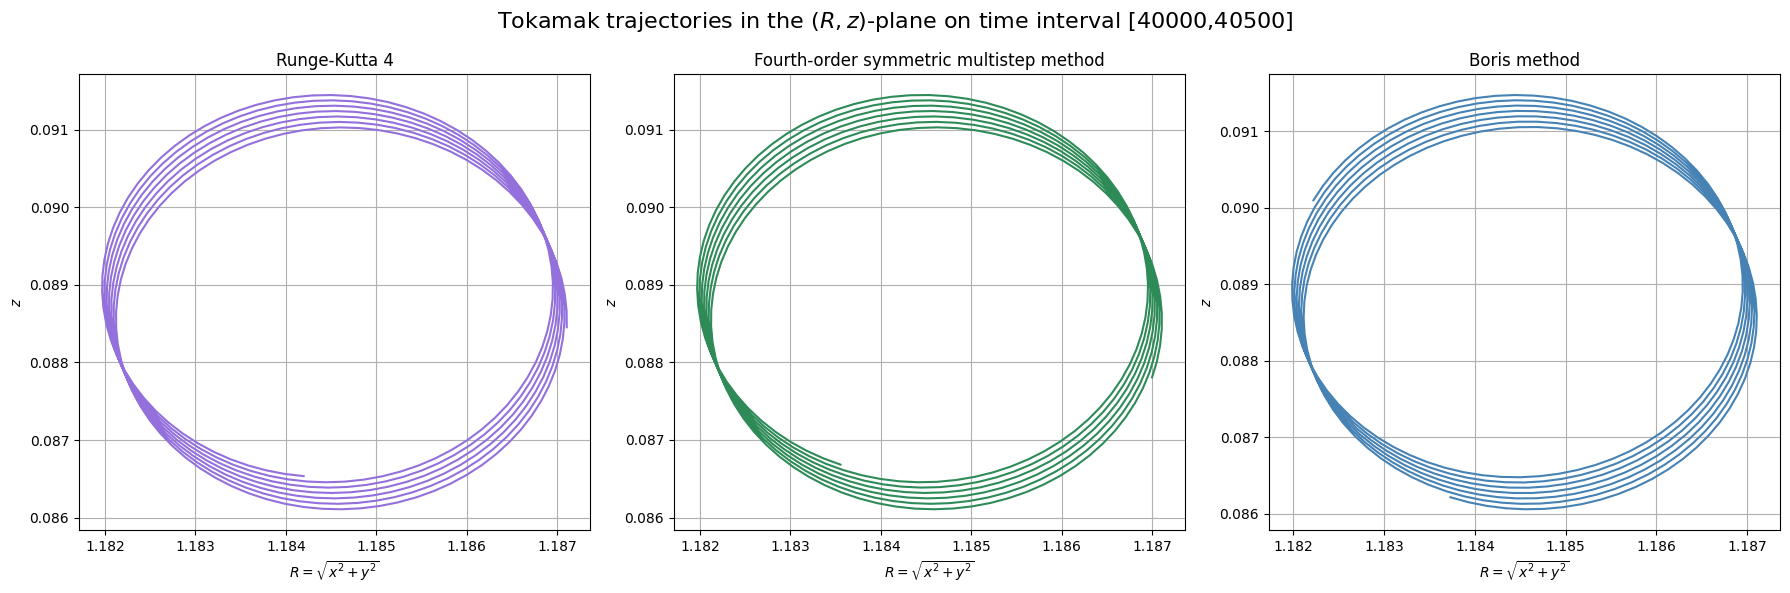

In [100]:
#Zooomed in interval
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(R[40000:40500], x3_amanda[40000:40500], color="mediumpurple")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x2_seline[0, :]**2 + x2_seline[1, :]**2)[40000:40500], x2_seline[2, :][40000:40500], color="seagreen")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris[40000:40500], z[40000:40500], color="steelblue")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


fig.suptitle("Tokamak trajectories in the $(R, z)$-plane on time interval [40000,40500]", fontsize=16)
plt.tight_layout()
plt.show()

# 5. Task A: Referanseløsninger og feil over tid

## Computing and comparing reference solutions for Boris

In [101]:
T_emilie = 10**5
h_emilie = 0.1
t_span_emilie = (0, T_emilie)
t_eval_emilie = np.arange(1, N_emilie+1) * h_emilie   # x_array[:, k] fra boris_method er posisjonen ved t = (k+1)h
print(len(t_eval_emilie))

initial_condition_2D_emilie = np.concatenate((x0_2D,v0_2D))
initial_condition_toko = np.concatenate((x0_tokamak,v0_tokamak))

sol = solve_ivp(ODEs, t_span_emilie, initial_condition_2D_emilie,
                args=(B_2D, grad_U_2D),
                method="DOP853", rtol=1e-10, atol=1e-12, t_eval=t_eval_emilie)



1000000


In [102]:
sol_toko = solve_ivp(ODEs, t_span_emilie, initial_condition_toko,
                args=(B_tokamak, grad_U_tokamak),
                method="DOP853", rtol=1e-10, atol=1e-12, t_eval=t_eval_emilie)

In [103]:
x1_emilie,x2_emilie,x3_emilie = sol.y[0:3]

error_boris_2d= np.linalg.norm(x_array_boris - sol.y[0:3], axis = 0, ord = 2)



In [104]:
error_toko_boris = np.linalg.norm(x_array_boris_toko - sol_toko.y[0:3], axis = 0, ord = 2)


## Computing and comparing reference solutions for RK4

---------------------------------------------------------------------------

In [105]:
#Plotting the error over time for the RK4 method
t_span_amanda = (0, T_amanda)
t_eval_amanda = np.arange(0, T_amanda+h_amanda, h_amanda)

initial_condition_2D_amanda = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))

sol_2D_amanda = scipy.integrate.solve_ivp(ODEs, t_span_amanda, initial_condition_2D_amanda, 
                                   args=(B_2D, grad_U_2D),
                                   method = 'DOP853',
                                   rtol = 1e-10,
                                   atol=1e-12,
                                   t_eval = t_eval_amanda)

sol_tokamak= scipy.integrate.solve_ivp(ODEs, t_span_amanda, initial_condition_tokamak, 
                                   args=(B_tokamak, grad_U_tokamak),
                                   method = 'DOP853',
                                   rtol = 1e-10,
                                   atol=1e-12,
                                   t_eval = t_eval_amanda)


print(sol_2D_amanda.success, sol_2D_amanda.message)
print(sol_tokamak.success, sol_tokamak.message)




True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.


In [106]:
#Plotting the error over time for both 2D paticle model
#Transposing to switch the rows and columns to make the shapes match


error_2D_amanda = np.linalg.norm(x_arr_2D - sol_2D_amanda.y[:3, :].T, axis = 1)




#Plotting the error over time for both Tokamak magnetic field
#Transposing to switch the rows and columns to make the shapes match
error_tokamak = np.linalg.norm(x_arr_tokamak - sol_tokamak.y[:3, :].T, axis = 1)




## Computing and comparing reference solutions for FOSMM

In [107]:
t_span_seline = (0, T_max)
N_seline = int(T_max/h_seline) + 1 
t_eval_seline = np.linspace(0, T_max, N_seline)

sol_2D_seline = solve_ivp(ODEs, t_span_seline, np.concatenate(y01),
    args=(B_2D, grad_U_2D),
    method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval_seline)

sol_toka = solve_ivp(ODEs, t_span_seline, np.concatenate(y02),
    args=(B_tokamak, grad_U_tokamak),
    method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval_seline)


Computing and plotting error:

In [108]:
def error(x, xref):
    return np.linalg.norm(x-xref, ord=2, axis = 0)

error1_FOSMM = error(x1_seline, sol_2D_seline.y[:3])
error2_FOSMM = error(x2_seline, sol_toka.y[:3])


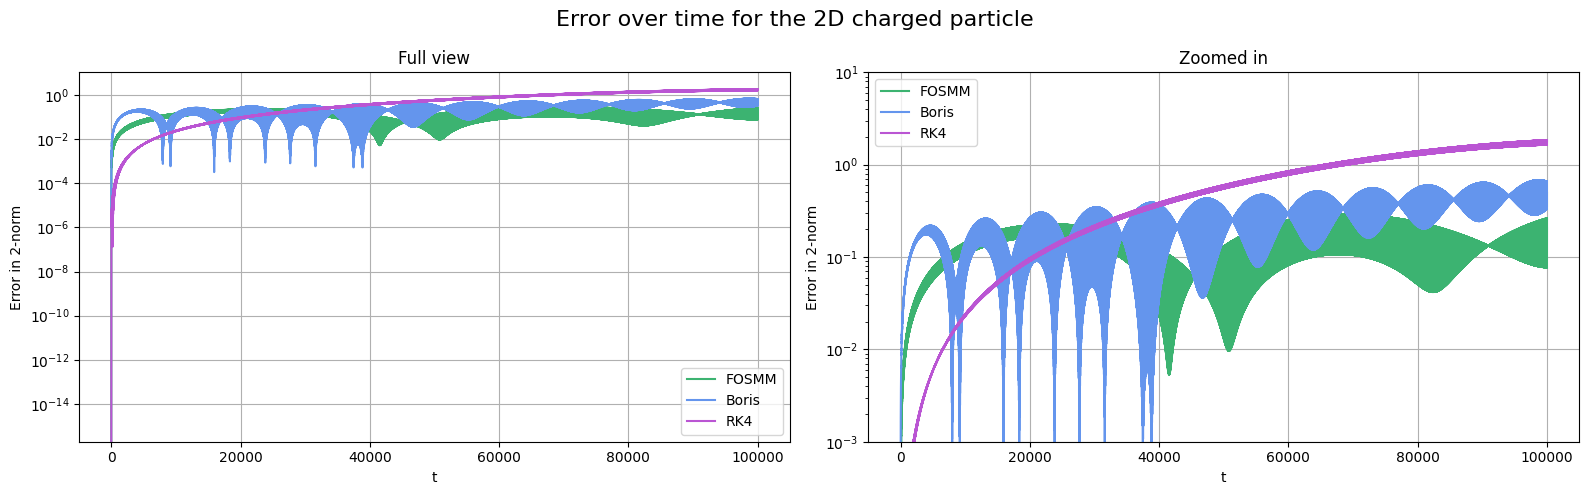

In [109]:
# ERROR FOR 2D-PARTICLE IN DIFFERENT MODELS:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax in axes:
    ax.semilogy(np.linspace(0, T_max, len(error1_FOSMM)), error1_FOSMM, color='mediumseagreen', label='FOSMM')
    ax.semilogy(t_eval_emilie, error_boris_2d, color='cornflowerblue', label='Boris')
    ax.semilogy(t_eval_amanda, error_2D_amanda, color='mediumorchid', label='RK4')
    ax.set_xlabel('t')
    ax.set_ylabel('Error in 2-norm')
    ax.legend()
    ax.grid(True)

axes[0].set_title('Full view')
axes[1].set_title('Zoomed in')
axes[1].set_ylim(1e-3, 1e1)

fig.suptitle('Error over time for the 2D charged particle', fontsize=16)
plt.tight_layout()
plt.show()




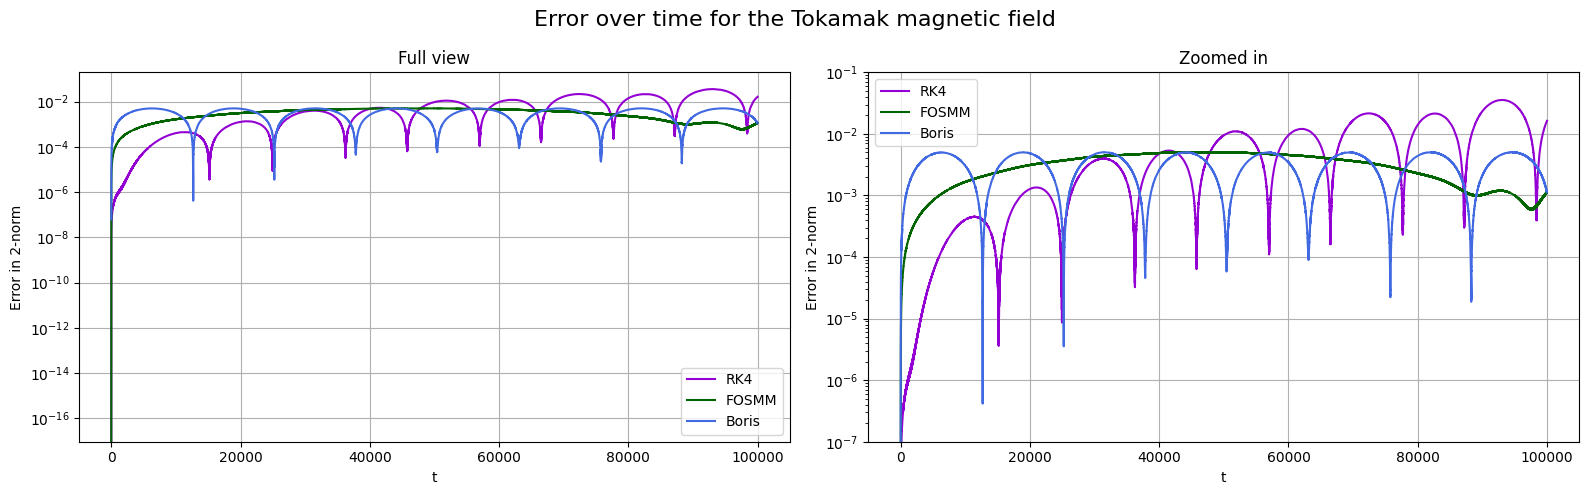

In [110]:
# ERROR OVER TIME FOR TOKAMAK FIELD WITH DIFFERENT METHODS:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax in axes:
    ax.semilogy(t_eval_amanda, error_tokamak, color='darkviolet', label='RK4')
    ax.semilogy(np.linspace(0, T_max, len(error2_FOSMM)), error2_FOSMM, color='darkgreen', label='FOSMM')
    ax.semilogy(t_eval_emilie, error_toko_boris, color='royalblue', label='Boris')
    ax.set_xlabel('t')
    ax.set_ylabel('Error in 2-norm')
    ax.legend()
    ax.grid(True)

axes[0].set_title('Full view')
axes[1].set_title('Zoomed in')
axes[1].set_ylim(1e-7, 1e-1)   # juster grensene etter hvordan plottet ser ut

fig.suptitle('Error over time for the Tokamak magnetic field', fontsize=16)
plt.tight_layout()
plt.show()


# 6. Task A: Energi

## Emilie (Boris)

In [111]:
def energy_change_boris(x,v, initial_values, U):

    v_at_integers = 0.5* (v[:,:-1] + v[:, 1:])


    energy_at_zero = energy(initial_values[0:3], initial_values[3:], U)

    x_array = x[:, :-1]

    energy_at_x_v = energy(x_array, v_at_integers, U)

    diff = np.abs(energy_at_x_v - energy_at_zero)

    return diff

energy_change_boris_2D = energy_change_boris(x_array_boris, v_array_boris, initial_condition_2D_emilie, U_2D)
energy_change_boris_toko = energy_change_boris(x_array_boris_toko, v_array_boris_toko, initial_condition_toko, U_tokamak)

t_eval_boris = t_eval_emilie[:-1]


## Amanda (RK4)

---------------------------------------------------------------

In [112]:
#Plotting the change in energy againt time 
#The energy function is defined together with the model problems

initial_condition_2D_amanda = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))

E0_2D = energy(initial_condition_2D_amanda[:3], initial_condition_2D_amanda[3:], U_2D)
E0_tokamak = energy(initial_condition_tokamak[:3], initial_condition_tokamak[3:], U_tokamak)

#Calculating the change in energy
e_n_2D = np.abs(energy(x_arr_2D.T, v_arr_2D.T, U_2D) - E0_2D)
e_n_tokamak = np.abs(energy(x_arr_tokamak.T, v_arr_tokamak.T, U_tokamak) - E0_tokamak)



## Seline (FOSMM)

compare to theorem: h^-7 = 10^7 so should hold for the entire time interval, which it does, as we can see both errors are below the O(h^4) limit.

compare results 

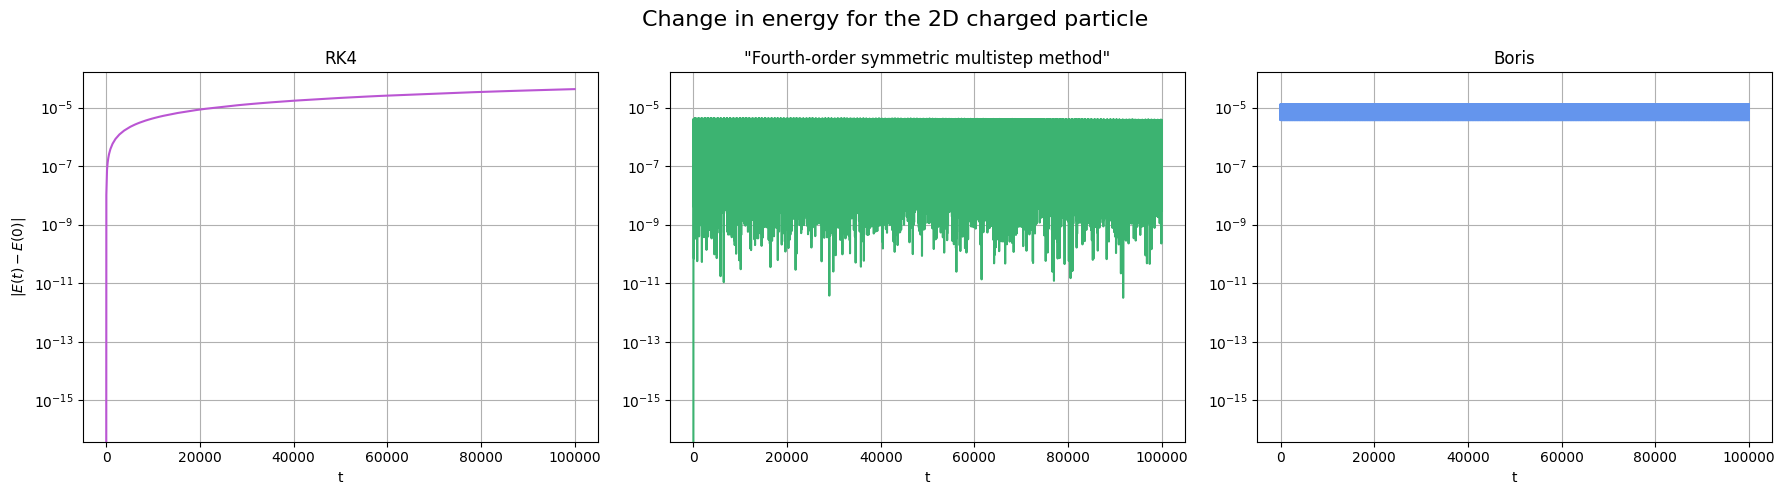

In [113]:
# ENERGY CHANGE FOR THE 2D PARTICLE, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)


#RK4
axes[0].semilogy(t_eval_amanda, e_n_2D, color='mediumorchid')
axes[0].set_title('RK4')

#FOSMM
axes[1].semilogy(t_eval_seline, energy_change(x1_seline, v1, U_2D), color='mediumseagreen')
axes[1].set_title('"Fourth-order symmetric multistep method"')

#Boris
axes[2].semilogy(t_eval_boris, energy_change_boris_2D, color='cornflowerblue')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('t')
    ax.grid(True)
    ax.tick_params(labelleft=True)
axes[0].set_ylabel(r'$|E(t) - E(0)|$')

fig.suptitle('Change in energy for the 2D charged particle', fontsize=16)
plt.tight_layout()
plt.show()



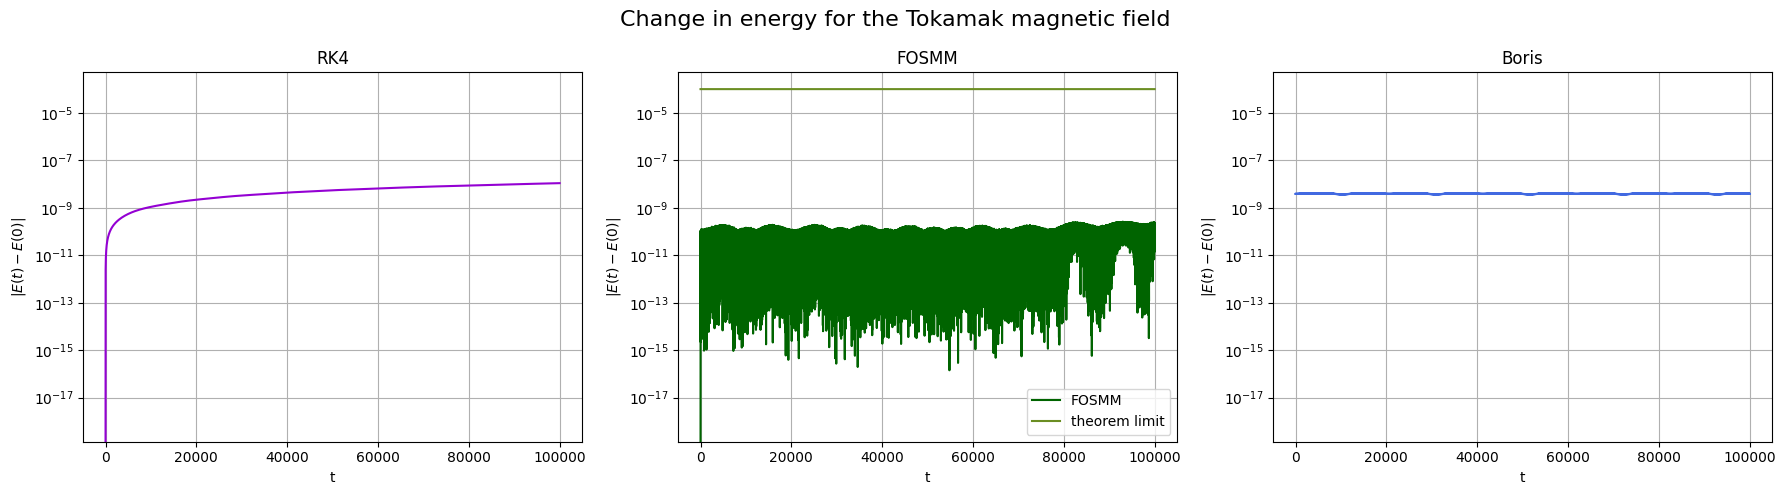

In [114]:
# ENERGY CHANGE FOR THE TOKAMAK FIELD, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

#RK4
axes[0].semilogy(t_eval_amanda, e_n_tokamak, color='darkviolet')
axes[0].set_title('RK4')

#FOSMM
axes[1].semilogy(t_eval_seline, energy_change(x2_seline, v2, U_tokamak), color='darkgreen', label='FOSMM')
axes[1].semilogy(t_eval_seline, h_seline**4*np.ones(len(t_eval_seline)), color='olivedrab', label='theorem limit')
axes[1].set_title('FOSMM')
axes[1].legend()

#Boris
axes[2].semilogy(t_eval_boris, energy_change_boris_toko, color='royalblue')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('t')
    ax.grid(True)
    ax.tick_params(labelleft=True)
    ax.set_ylabel(r'$|E(t) - E(0)|$')
axes[0].set_ylabel(r'$|E(t) - E(0)|$')

fig.suptitle('Change in energy for the Tokamak magnetic field', fontsize=16)
plt.tight_layout()
plt.show()

SAMMENLIKN ALLE RESULTATER MED FORVENTNINGER! se oppgaveteksten


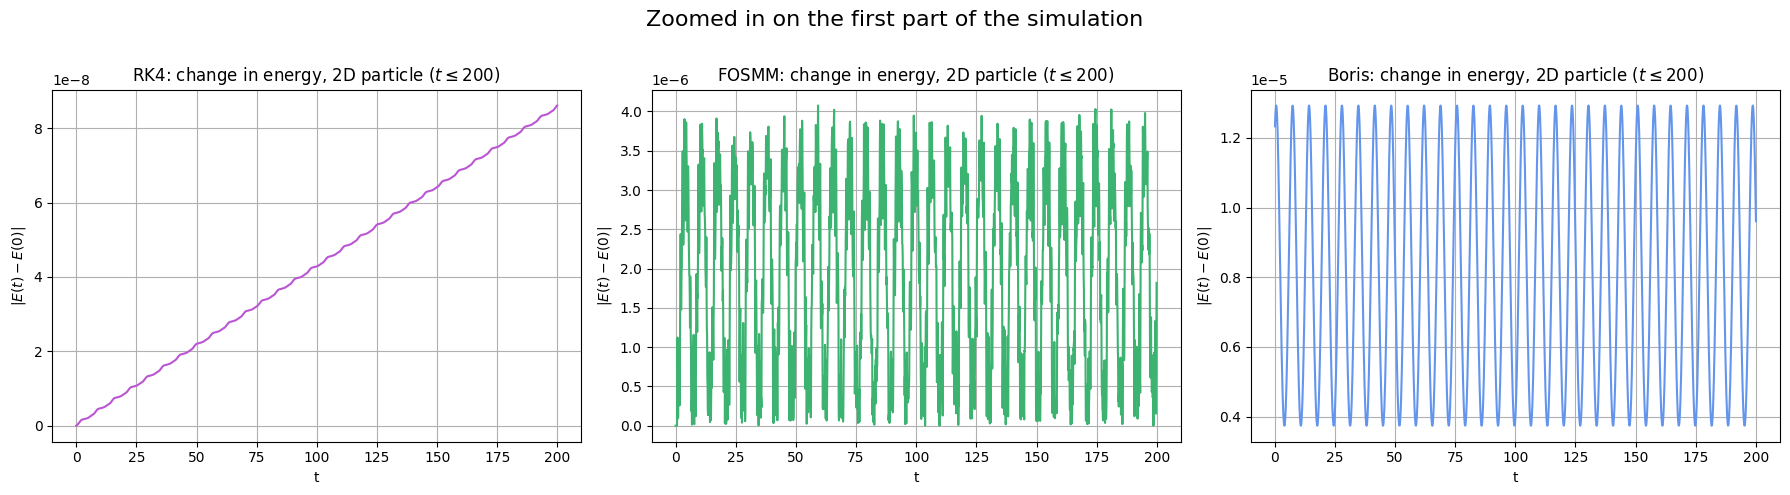

In [115]:
# ZOOMED-IN PLOTS OVER A SHORT TIME INTERVAL
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4: energy change

axes[0].plot(t_eval_amanda[:2000], e_n_2D[:2000], color="mediumorchid")
axes[0].set_title("RK4: change in energy, 2D particle ($t \\leq 200$)")
axes[0].set_xlabel("t")
axes[0].set_ylabel(r"$|E(t) - E(0)|$")

#FOSMM: energy change
axes[1].plot(t_eval_seline[:2000], energy_change(x1_seline[:,:200*10], v1[:,:200*10], U_2D), color="mediumseagreen")
axes[1].set_title("FOSMM: change in energy, 2D particle ($t \\leq 200$)")
axes[1].set_xlabel("t")
axes[1].set_ylabel(r"$|E(t) - E(0)|$")

#Boris: energy change
axes[2].plot(t_eval_emilie[:2000], energy_change_boris_2D[:2000], color="cornflowerblue")
axes[2].set_title("Boris: change in energy, 2D particle ($t \\leq 200$)")
axes[2].set_xlabel("t")
axes[2].set_ylabel(r"$|E(t) - E(0)|$")

for ax in axes:
    ax.grid(True)

fig.suptitle("Zoomed in on the first part of the simulation", fontsize=16)
plt.tight_layout()
plt.show()

# 7. Task B: Konvergens og work-precision

## Emilie (Boris)

In [116]:
def error_boris_decrease(T_emilie):
    h_emilie = 0.1
    h_i_emilie = [h_emilie, h_emilie/2, h_emilie/4]
    #T_emilie = 10**3
    errors_2d = []
    errors_toko = []
    time_list_2d = []
    time_list_toka = []

    for i in range(3):
        N_i = int(T_emilie/h_i_emilie[i])   # samme antall steg som RK4 og FOSMM, slutter ved T

        t_span_emilie = (0,T_emilie)
        t_eval_emilie = np.arange(1, N_i+1) * h_i_emilie[i]   # x_array[:, k] fra boris_method er posisjonen ved t = (k+1)h

        x_boris_2D, y_boris_2D, time_2d = boris_method(ODEs,x0_2D,v0_2D,h_i_emilie[i],U_2D, grad_U_2D,B_2D, True, N_i)
        

        sol_2D = solve_ivp(ODEs, t_span_emilie, initial_condition_2D_emilie,
                args=(B_2D, grad_U_2D),
                method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval_emilie)

        
        x_boris_toko, y_boris_toka, time_toka = boris_method(ODEs,x0_tokamak,v0_tokamak,h_i_emilie[i],U_tokamak, grad_U_tokamak,B_tokamak, True, N_i)

        time_list_2d.append(time_2d)
        time_list_toka.append(time_toka)


        sol_toko = solve_ivp(ODEs, t_span_emilie, initial_condition_toko,
                args=(B_tokamak, grad_U_tokamak),
                method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval_emilie)

        # Compare last step global error

        x_last_2D = x_boris_2D[:,-1]
        x_last_2D_ref = sol_2D.y[:3][:,-1]

        x_last_toko = x_boris_toko[:,-1]
        x_last_toko_ref = sol_toko.y[:3][:,-1]

        norm_2D = np.linalg.norm(x_last_2D - x_last_2D_ref, ord = 2, axis = 0)
        norm_toko = np.linalg.norm(x_last_toko - x_last_toko_ref, ord = 2, axis = 0)

        errors_2d.append(norm_2D)
        errors_toko.append(norm_toko)

    return errors_2d, errors_toko, time_list_2d, time_list_toka


In [142]:
T_emilie = [1e4, 1e3, 1e2, 10]
error_2D_emilie_T1, error_toka_T1, time_2d_T1, time_toka_T1 = error_boris_decrease(T_emilie[0])
error_2D_emilie_T2, error_toka_T2, time_2d_T2, time_toka_T2 = error_boris_decrease(T_emilie[1])
error_2D_emilie_T3, error_toka_T3, time_2d_T3, time_toka_T3 = error_boris_decrease(T_emilie[2])
error_2D_emilie_T4, error_toka_T4, time_2d_T4, time_toka_T4 = error_boris_decrease(T_emilie[3])



In [143]:

h_i_emilie = [h_emilie, h_emilie/2, h_emilie/4]
h_p = [i**2 for i in h_i_emilie]



## Amanda (RK4)

## Task B) Order verification and work precision diagrams

In [119]:

#Paramaters
h_amanda = 0.1
h_i_amanda = np.array([h_amanda, h_amanda/2 , h_amanda/4])


T_amanda = 1e4
N_i = (T_amanda/h_i_amanda).astype(int)

for i in range(3):
    print(h_i_amanda[i], N_i[i]*h_i_amanda[i])

#2D
# Preallocating arrays
y_arr_2D_i = [
    np.zeros((N_i[0] + 1, 6)),
    np.zeros((N_i[1] + 1, 6)), 
    np.zeros((N_i[2] + 1, 6))
    ]

# Initial condition: position + velocity
y0 = np.concatenate((np.asarray(x0_2D), np.asarray(v0_2D)))
                          
for i in range(3):
    y_arr_2D_i[i][0] = y0


tau_2D_i = []

for i in range(3):
    #Resetting y_n before each simulation
    y_n = np.concatenate((x0_2D, v0_2D))

    start = pytime.perf_counter()
    for j in tqdm(range(N_i[i])):
        y_n = RK4_amanda(y_n, h_i_amanda[i], B_2D, grad_U_2D)
        y_arr_2D_i[i][j+1] = np.asarray(y_n)

    end = pytime.perf_counter()
    tau_2D_i.append(end-start)
    

# Extracting position and velocity
x_arr_2D_i = [y[:, :3] for y in y_arr_2D_i]
v_arr_2D_i =[y[:, 3:] for y in y_arr_2D_i]



0.1 10000.0
0.05 10000.0
0.025 10000.0


100%|██████████| 400000/400000 [00:26<00:00, 15020.92it/s]


In [120]:
#Tokamak
# Preallocating array
y_arr_tokamak_i = [
    np.zeros((N_i[0] + 1, 6)),
    np.zeros((N_i[1] + 1, 6)), 
    np.zeros((N_i[2] + 1, 6))
    ]


# Initial condition: position + velocity
y0 = np.concatenate((np.asarray(x0_tokamak), np.asarray(v0_tokamak)))

for i in range(3):
    y_arr_tokamak_i[i][0] = y0

tau_tokamak_i = []

for i in range(3):
    #Resetting y_n before each simulation
    y_n = np.concatenate((x0_tokamak, v0_tokamak))

    start = pytime.perf_counter()

    for j in tqdm(range(N_i[i])):
        y_n = RK4_amanda(y_n, h_i_amanda[i], B_tokamak, grad_U_tokamak)
        y_arr_tokamak_i[i][j+1] = np.asarray(y_n)
    end = pytime.perf_counter()
    tau_tokamak_i.append(end-start)


# Extracting position and velocity
x_arr_tokamak_i = [y[:, :3] for y in y_arr_tokamak_i]
v_arr_tokamak_i =[y[:, 3:] for y in y_arr_tokamak_i]

print(tau_tokamak_i)

100%|██████████| 400000/400000 [00:27<00:00, 14546.11it/s]

[7.30902333301492, 13.771088458946906, 27.50105912500294]


In [121]:
#Solve_ivp for all three step sizes
sol_2D_i = []
sol_tokamak_i = []

for i in range(3):
    t_eval_i = np.arange(0, T_amanda + h_i_amanda[i]/2, h_i_amanda[i])
    sol_2D_i.append(
        scipy.integrate.solve_ivp(ODEs, (0, T_amanda), initial_condition_2D_amanda, 
                args=(B_2D, grad_U_2D),
                method = 'DOP853',
                rtol = 1e-12,
                atol=1e-14,
                t_eval = t_eval_i)

    )
    
    sol_tokamak_i.append(
        scipy.integrate.solve_ivp(ODEs, (0, T_amanda), initial_condition_tokamak, 
                args=(B_tokamak, grad_U_tokamak),
                method = 'DOP853',
                rtol = 1e-12,
                atol=1e-14,
                t_eval = t_eval_i)

    )
    

for i in range(3):
    print(f"h = {h_i_amanda[i]}:")
    print(sol_2D_i[i].success, sol_2D_i[i].message)
    print(sol_tokamak_i[i].success, sol_tokamak_i[i].message)

h = 0.1:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.
h = 0.05:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.
h = 0.025:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.


In [122]:
def error_RK4_decrease(T):

    # Parameters
    h_amanda = 0.1
    h_i_amanda = np.array([h_amanda, h_amanda/2, h_amanda/4])
    N_i = (T / h_i_amanda).astype(int)

    # Initial conditions
    initial_condition_2D_amanda = np.concatenate((x0_2D, v0_2D))
    initial_condition_tokamak = np.concatenate((x0_tokamak, v0_tokamak))

    # Reference solutions at final time T
    sol_2D = scipy.integrate.solve_ivp(
        ODEs, (0, T), initial_condition_2D_amanda,
        args=(B_2D, grad_U_2D),
        method='DOP853',
        rtol=1e-12,
        atol=1e-14,
        t_eval=[T]
    )

    sol_tokamak = scipy.integrate.solve_ivp(
        ODEs, (0, T), initial_condition_tokamak,
        args=(B_tokamak, grad_U_tokamak),
        method='DOP853',
        rtol=1e-12,
        atol=1e-14,
        t_eval=[T]
    )

    # Lists for errors and computation times
    error_2D = []
    error_tokamak = []
    time_2D = []
    time_tokamak = []

    # RK4 for each step size: 2D and Tokamak
    for i in range(3):

        # 2D
        y_n = initial_condition_2D_amanda.copy()

        start = pytime.perf_counter()

        for j in range(N_i[i]):
            y_n = RK4_amanda(
                y_n, h_i_amanda[i], B_2D, grad_U_2D
            )

        end = pytime.perf_counter()
        time_2D.append(end - start)

        error_2D.append(
            np.linalg.norm(y_n[:3] - sol_2D.y[:3, -1])
        )

        # Tokamak
        y_n = initial_condition_tokamak.copy()

        start = pytime.perf_counter()

        for j in range(N_i[i]):
            y_n = RK4_amanda(
                y_n, h_i_amanda[i], B_tokamak, grad_U_tokamak
            )

        end = pytime.perf_counter()
        time_tokamak.append(end - start)

        error_tokamak.append(
            np.linalg.norm(y_n[:3] - sol_tokamak.y[:3, -1])
        )

    return error_2D, error_tokamak, time_2D, time_tokamak

In [144]:
T_RK4 = [1e4, 1e3, 1e2, 10]

error_2D_RK4_T1, error_toka_RK4_T1, time_2D_RK4_T1, time_toka_RK4_T1 = error_RK4_decrease(T_RK4[0])
error_2D_RK4_T2, error_toka_RK4_T2, time_2D_RK4_T2, time_toka_RK4_T2 = error_RK4_decrease(T_RK4[1])
error_2D_RK4_T3, error_toka_RK4_T3, time_2D_RK4_T3, time_toka_RK4_T3 = error_RK4_decrease(T_RK4[2])
error_2D_RK4_T4, error_toka_RK4_T4, time_2D_RK4_T4, time_toka_RK4_T4 = error_RK4_decrease(T_RK4[3])

In [124]:
#Comuting the error in the last step
error_2D_i = []

for i in range(3):
    error_2D_i.append(np.linalg.norm(x_arr_2D_i[i][-1, :] - sol_2D_i[i].y[:3, -1]))


error_tokamak_i = []

for i in range(3):
    error_tokamak_i.append(np.linalg.norm(x_arr_tokamak_i[i][-1, :] - sol_tokamak_i[i].y[:3, -1]))





## Seline (FOSMM)

Task B) FOSMM

In [125]:
T_seline_vals = [1e4, 1e3, 1e2, 10]
h_seline = 0.1
#2D particle (1) and Tokamak field (2)
e1 = []
e2 = []
t1 = []
t2 = []
h_arr = []
for T_seline in T_seline_vals:
    for i in range(3):
        hi = h_seline/2**i
        h_arr.append(hi)
        N_seline = int(T_seline/hi) + 1 
        t_span_seline = (0,T_seline)
        t_eval_seline_B = np.linspace(0,T_seline, N_seline)
        xi1, _ , ti1 = FOSMM(alpha, hi, A_2D, grad_U_2D, B_2D, beta, T_seline, y01)
        xi2, _ , ti2 = FOSMM(alpha, hi, A_tokamak, grad_U_tokamak, B_tokamak, beta, T_seline, y02)

        xi1_ref_sol = solve_ivp(ODEs, t_span_seline, np.concatenate(y01), args=(B_2D, grad_U_2D), method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval_seline_B)
        xi2_ref_sol = solve_ivp(ODEs, t_span_seline, np.concatenate(y02), args=(B_tokamak, grad_U_tokamak),method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval_seline_B)

        xi1_ref = xi1_ref_sol.y[:3]
        xi2_ref = xi2_ref_sol.y[:3]

        t1.append(ti1)
        t2.append(ti2)

        e1.append(np.linalg.norm(xi1[:,-1] - xi1_ref[:,-1], ord=2, axis=0))
        e2.append(np.linalg.norm(xi2[:,-1] - xi2_ref[:,-1], ord=2, axis=0))
h_arr = np.array(h_arr)

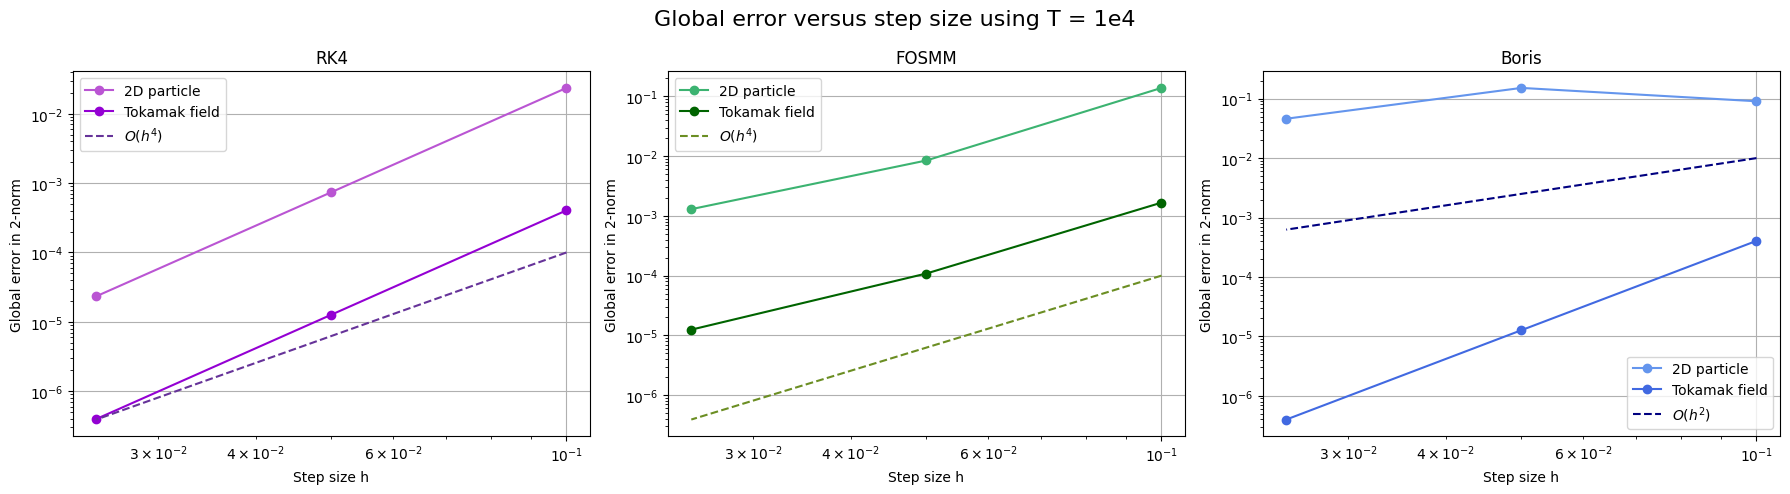

In [ ]:

# GLOBAL ERROR VS STEP SIZE, T = 1e-4, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_i_amanda, error_2D_RK4_T1, 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_i_amanda, error_toka_T1, 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_i_amanda, h_i_amanda**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_arr[:3], e1[:3], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_arr[:3], e2[:3], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_arr[:3], h_arr[:3]**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_i_emilie, error_2D_emilie_T1, 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_i_emilie, error_toka_T1, 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_i_emilie, h_p, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Global error versus step size using T = 1e4', fontsize=16)
plt.tight_layout()
plt.show()

perhaps also weird for boris due to phase?

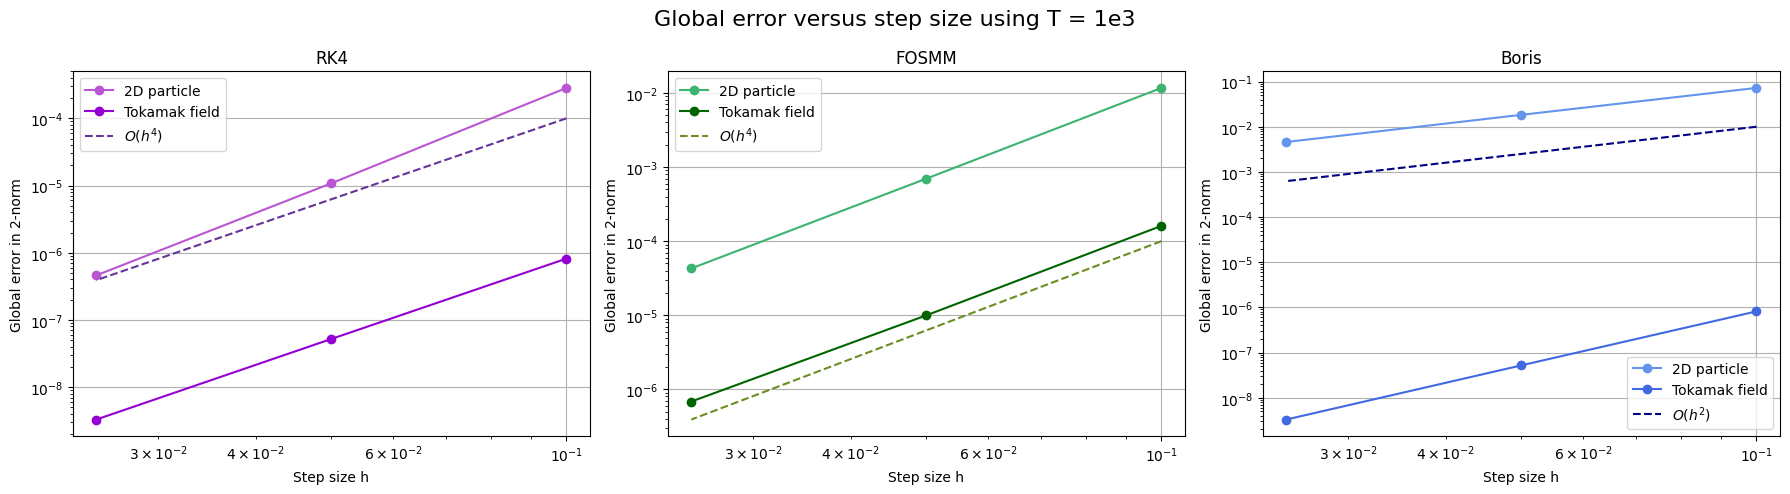

In [ ]:

# GLOBAL ERROR VS STEP SIZE, T = 1e3, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_i_amanda, error_2D_RK4_T2, 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_i_amanda, error_toka_T2, 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_i_amanda, h_i_amanda**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_arr[3:6], e1[3:6], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_arr[3:6], e2[3:6], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_arr[3:6], h_arr[3:6]**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_i_emilie, error_2D_emilie_T2, 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_i_emilie, error_toka_T2, 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_i_emilie, h_p, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Global error versus step size using T = 1e3', fontsize=16)
plt.tight_layout()
plt.show()

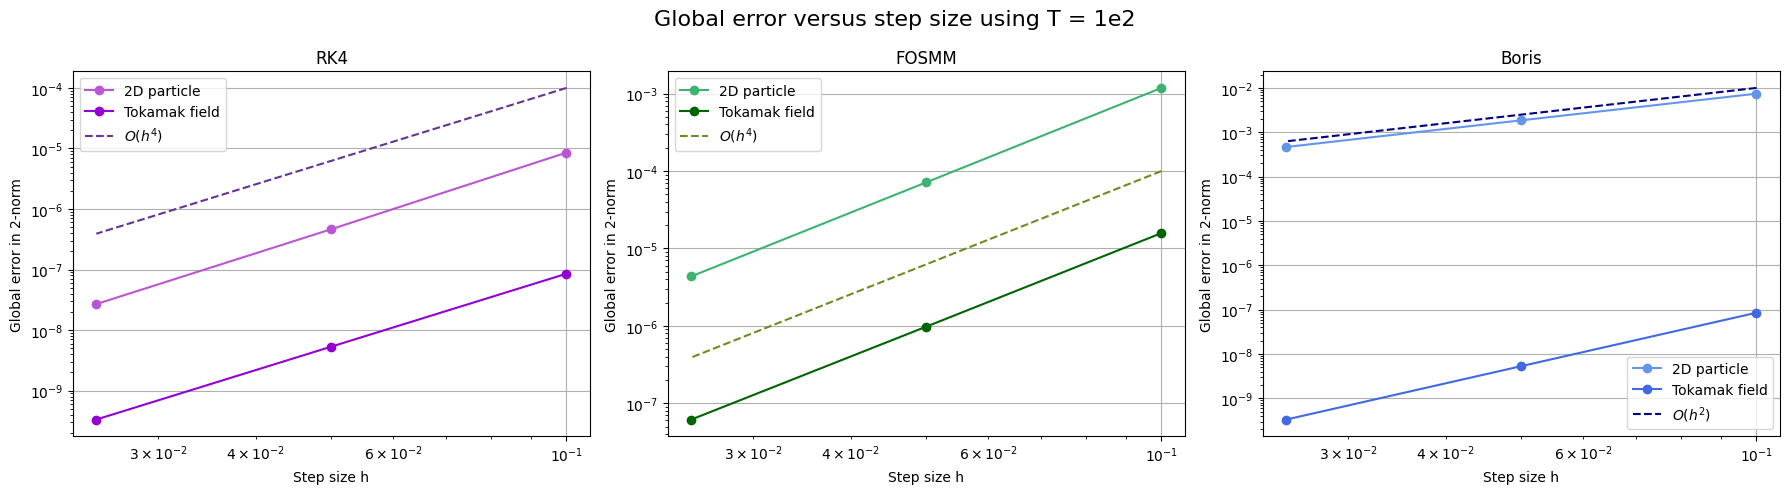

In [ ]:

# GLOBAL ERROR VS STEP SIZE, T = 1e2, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_i_amanda, error_2D_RK4_T3, 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_i_amanda, error_toka_T3, 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_i_amanda, h_i_amanda**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_arr[6:9], e1[6:9], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_arr[6:9], e2[6:9], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_arr[6:9], h_arr[6:9]**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_i_emilie, error_2D_emilie_T3, 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_i_emilie, error_toka_T3, 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_i_emilie, h_p, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Global error versus step size using T = 1e2', fontsize=16)
plt.tight_layout()
plt.show()

Text(0.5, 0.98, 'Global error versus step size using T = 10')

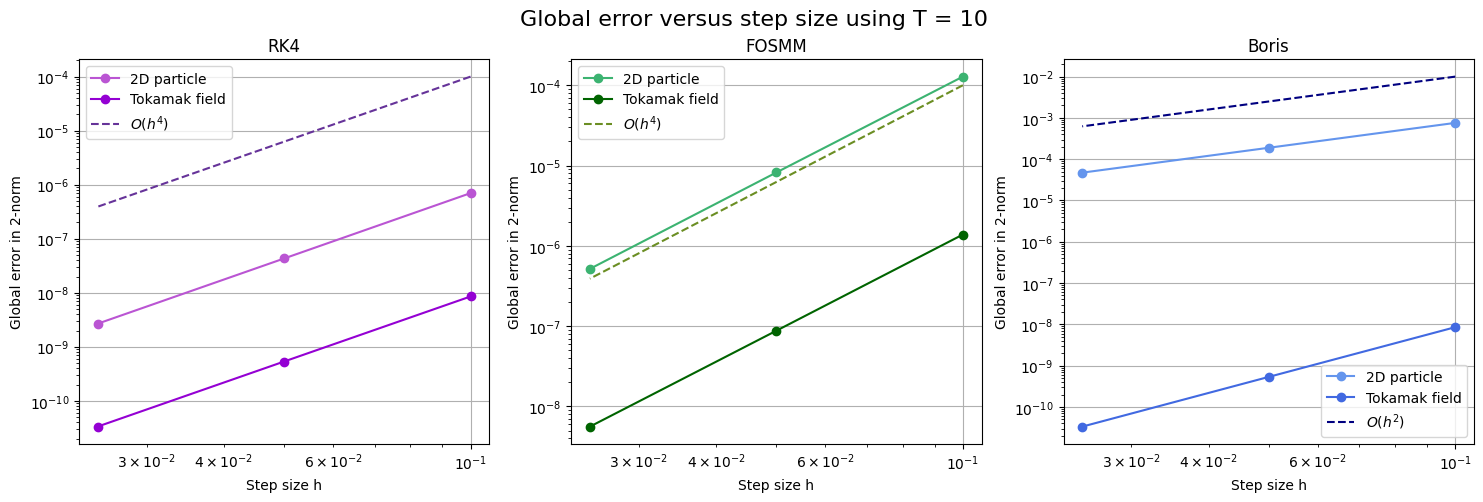

In [ ]:

# GLOBAL ERROR VS STEP SIZE, T = 10, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_i_amanda, error_2D_RK4_T4, 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_i_amanda, error_toka_T4, 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_i_amanda, h_i_amanda**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_arr[9:], e1[9:], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_arr[9:], e2[9:], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_arr[9:], h_arr[9:]**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_i_emilie, error_2D_emilie_T4, 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_i_emilie, error_toka_T4, 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_i_emilie, h_p, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Global error versus step size using T = 10', fontsize=16)

as we can see, the errors grow asymptotically as h**4

VISE MER ORDENTLIG???

fra øving 2: Compute Rn,0 for n= 0,1,2 (composite trapezoidal rule with 1, 2, and 4
subintervals). Verify that the errors are approximately in the ratio 4 : 1
when the step size is halved, consistent with O(h2) convergence.
DETTE MÅ FORKLARES
OI NEI MEN i følge argumentasjonen for RK4 så er jo da denne ikke orden 4??? For h < h0 vil de være større enn O(h^4)?

which method most efficient for a given tolerrance?

makes sense, more time = more accurcay and vice versa

since the plots of the error have a steeper slope than the h**4 plot, for some h0 >0 we will have that the errors are below Ch^4 for all h <= h0, thus the O(h^4) condition for convergence of order p is satisfied. 

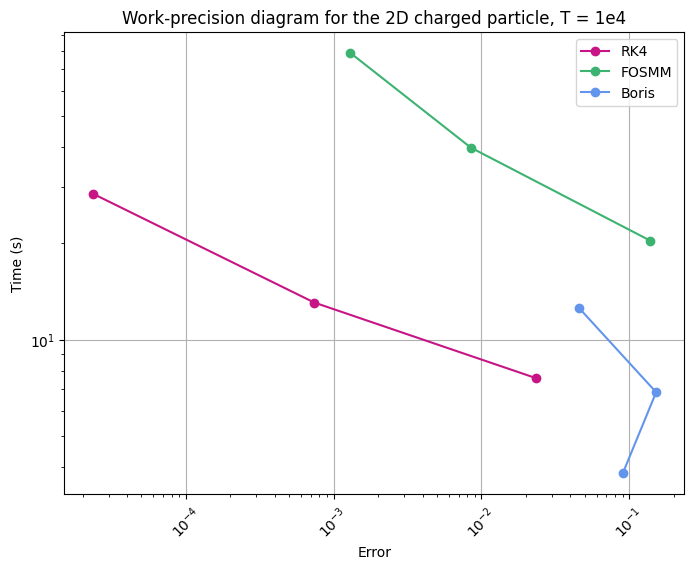

In [146]:
#2D error
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 1e4
plt.figure(figsize=(8, 6))

plt.loglog(error_2D_RK4_T1, time_2D_RK4_T1, 'o-', color='mediumvioletred', label='RK4')
plt.loglog(e1[:3], t1[:3], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(error_2D_emilie_T1, time_2d_T1, 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the 2D charged particle, T = 1e4')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()




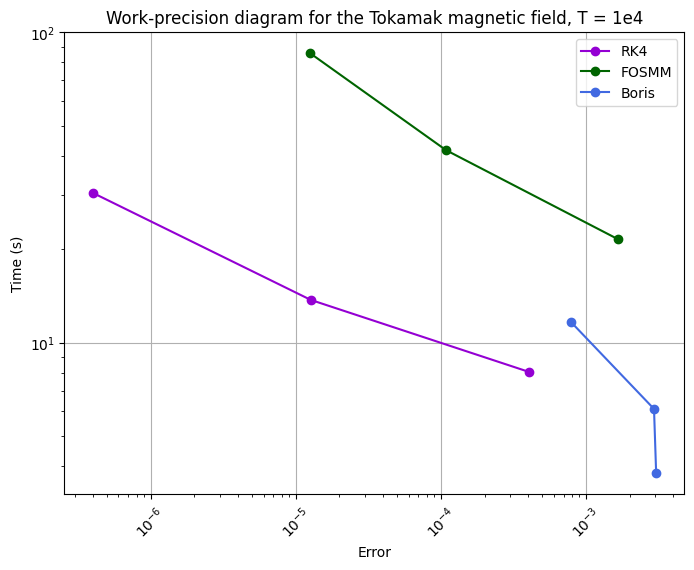

In [148]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 1e4
plt.figure(figsize=(8, 6))

plt.loglog(error_toka_RK4_T1,  time_toka_RK4_T1, 'o-', color='darkviolet', label='RK4')
plt.loglog(e2[:3], t2[:3], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(error_toka_T1, time_toka_T1, 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the Tokamak magnetic field, T = 1e4')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

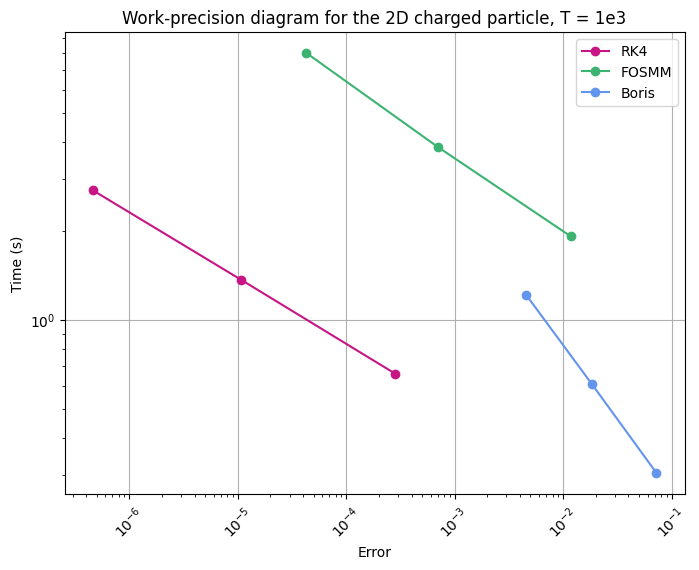

In [149]:
#2D error
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 1e3
plt.figure(figsize=(8, 6))

plt.loglog(error_2D_RK4_T2, time_2D_RK4_T2, 'o-', color='mediumvioletred', label='RK4')
plt.loglog(e1[3:6], t1[3:6], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(error_2D_emilie_T2, time_2d_T2, 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the 2D charged particle, T = 1e3')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()



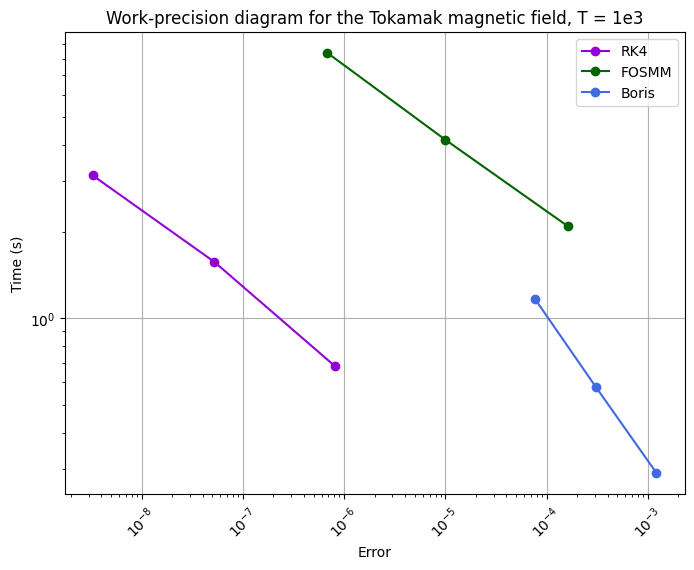

In [150]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 1e3
plt.figure(figsize=(8, 6))

plt.loglog(error_toka_RK4_T2, time_toka_RK4_T2, 'o-', color='darkviolet', label='RK4')
plt.loglog(e2[3:6], t2[3:6], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(error_toka_T2, time_toka_T2, 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the Tokamak magnetic field, T = 1e3')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

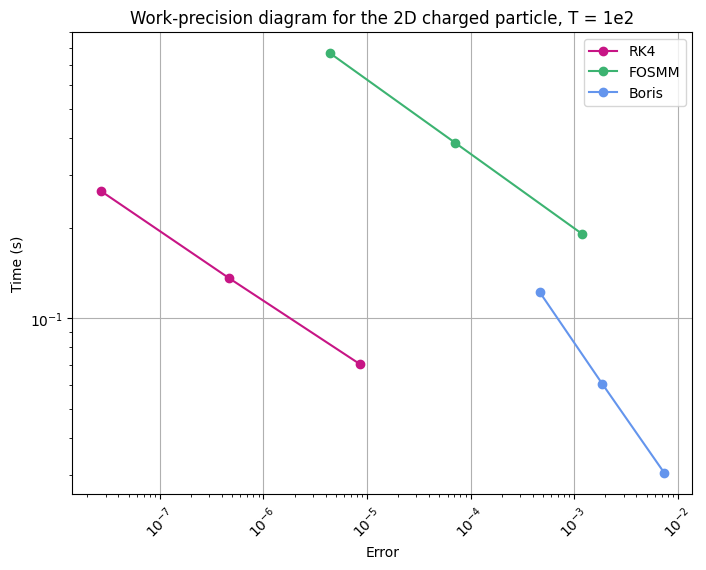

In [151]:
#2D error
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 1e2
plt.figure(figsize=(8, 6))

plt.loglog(error_2D_RK4_T3, time_2D_RK4_T3, 'o-', color='mediumvioletred', label='RK4')
plt.loglog(e1[6:9], t1[6:9], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(error_2D_emilie_T3, time_2d_T3, 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the 2D charged particle, T = 1e2')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()


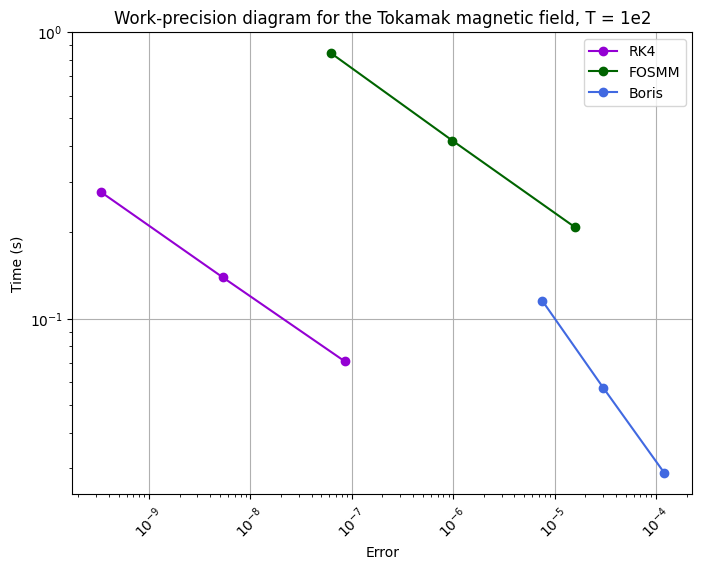

In [152]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 1e2
plt.figure(figsize=(8, 6))

plt.loglog(error_toka_RK4_T3, time_toka_RK4_T3, 'o-', color='darkviolet', label='RK4')
plt.loglog(e2[6:9], t2[6:9], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(error_toka_T3, time_toka_T3, 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the Tokamak magnetic field, T = 1e2')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

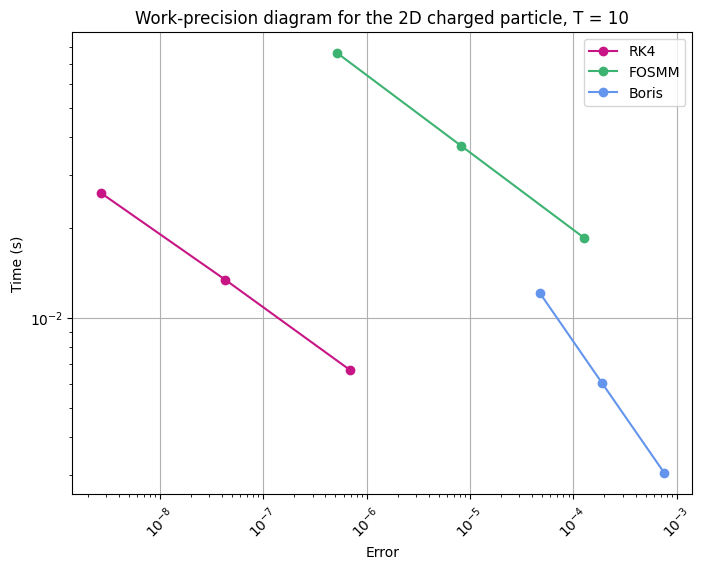

In [153]:
#2D error
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 10
plt.figure(figsize=(8, 6))

plt.loglog(error_2D_RK4_T4, time_2D_RK4_T4, 'o-', color='mediumvioletred', label='RK4')
plt.loglog(e1[9:], t1[9:], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(error_2D_emilie_T4, time_2d_T4, 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the 2D charged particle, T = 10')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()


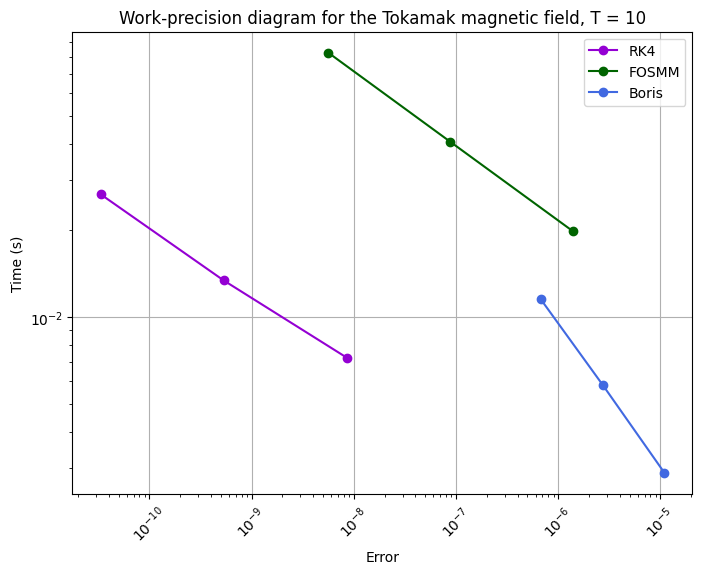

In [154]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 10
plt.figure(figsize=(8, 6))

plt.loglog(error_toka_RK4_T4, time_toka_RK4_T4, 'o-', color='darkviolet', label='RK4')
plt.loglog(e2[9:], t2[9:], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(error_toka_T4, time_toka_T4, 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Work-precision diagram for the Tokamak magnetic field, T = 10')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

-----------------------------

# Task C

## Task C RK4 method

In [80]:
# Parameters
T_C = 2e5
h_C = np.pi/10
n_steps = int(T_C/h_C)
time_C = np.linspace(0, T_C, n_steps + 1)

# Preallocating array
y_arr_tokamak_RK4_C = np.zeros((n_steps + 1, 6))

x0_tokamak_RK4_C = np.array([1.05, 0, 0])
v0_tokamak_RK4_C = np.array([0, 4.816e-4, -2.059e-3])

# Initial condition: position + velocity
y_arr_tokamak_RK4_C[0] = np.concatenate((
    np.asarray(x0_tokamak_RK4_C), np.asarray(v0_tokamak_RK4_C)))

y_n_RK4 = np.concatenate((x0_tokamak_RK4_C, v0_tokamak_RK4_C))

for i in tqdm(range(n_steps)):
    y_n_RK4 = RK4_amanda(y_n_RK4, h_C, B_tokamak, grad_U_tokamak)
    y_arr_tokamak_RK4_C[i+1] = np.asarray(y_n_RK4)

# Extracting position and velocity
x_arr_tokamak_RK4_C = y_arr_tokamak_RK4_C[:, :3]
v_arr_tokamak_RK4_C = y_arr_tokamak_RK4_C[:, 3:]

100%|██████████| 636619/636619 [00:44<00:00, 14356.50it/s]


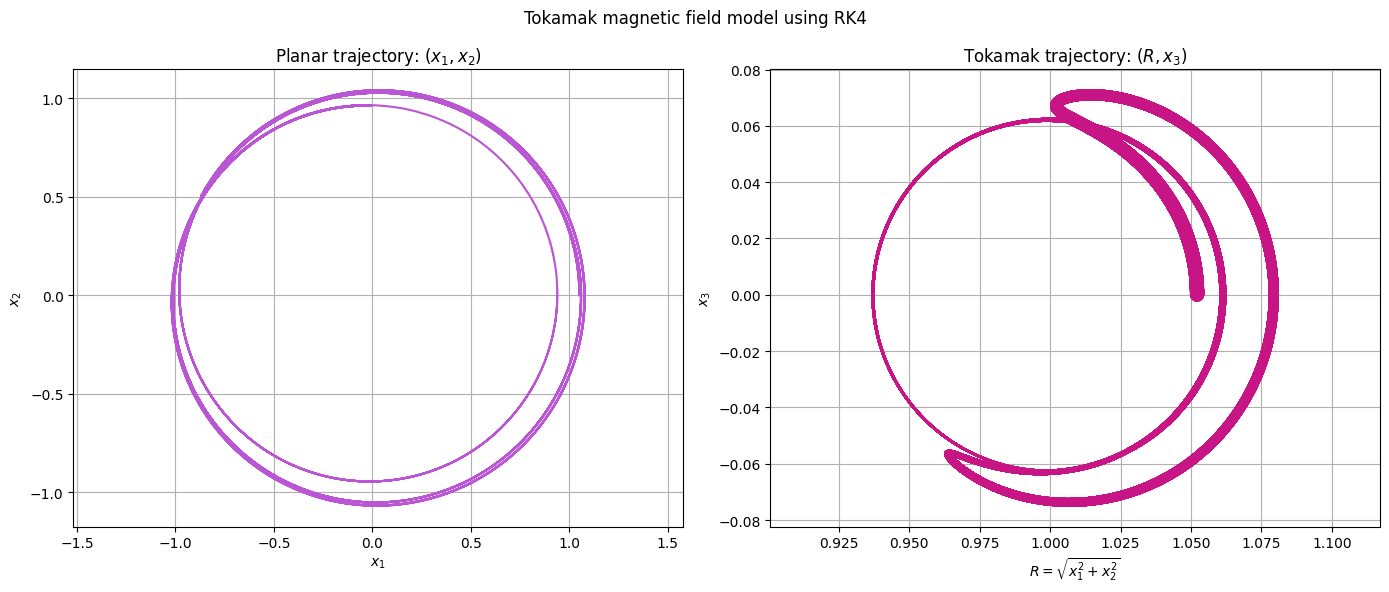

In [81]:
#Plotting the trajectories of the two first coordinates of the solutions
# Cylindrical radial coordinate
R_RK4_C = np.sqrt(x_arr_tokamak_RK4_C[:, 0]**2 + x_arr_tokamak_RK4_C[:, 1]**2)
x3_RK4_C = x_arr_tokamak_RK4_C[:, 2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Trajectory in the x1-x2 plane
axes[0].plot(x_arr_tokamak_RK4_C[:, 0],x_arr_tokamak_RK4_C[:, 1],color="mediumorchid")
axes[0].set_xlabel(r"$x_1$")
axes[0].set_ylabel(r"$x_2$")
axes[0].set_title(r"Planar trajectory: $(x_1,x_2)$")
axes[0].axis("equal")
axes[0].grid(True)

# Trajectory in the R-x3 plane
axes[1].plot(R_RK4_C,x3_RK4_C, color="mediumvioletred")
axes[1].set_xlabel(r"$R=\sqrt{x_1^2+x_2^2}$")
axes[1].set_ylabel(r"$x_3$")
axes[1].set_title(r"Tokamak trajectory: $(R,x_3)$")
axes[1].axis("equal")
axes[1].grid(True)

fig.suptitle("Tokamak magnetic field model using RK4")
plt.tight_layout()
plt.show()


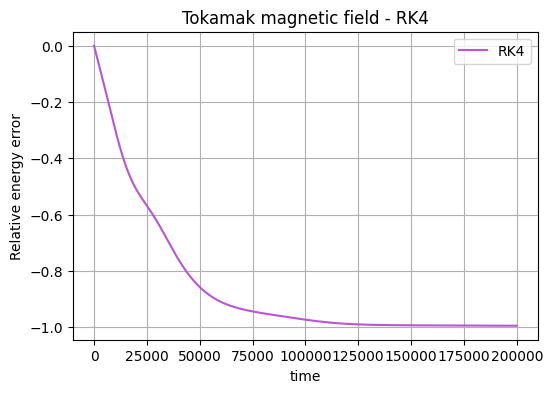

In [82]:
# Calculate relative energy error
E_n_tokamak_RK4_C = energy(x_arr_tokamak_RK4_C.T, v_arr_tokamak_RK4_C.T, U_tokamak)
E0_tokamak_RK4_C = E_n_tokamak_RK4_C[0]


error_energy_tokamak = (E_n_tokamak_RK4_C - E0_tokamak_RK4_C) / E0_tokamak_RK4_C


plt.figure(figsize=(6,4))

plt.plot(time_C, error_energy_tokamak,
         color='mediumorchid', label='RK4')

plt.xlabel('time')
plt.ylabel('Relative energy error')
plt.title('Tokamak magnetic field - RK4')
plt.grid(True)
plt.legend()
plt.show()

## Task C Boris method

In [ ]:
# Boris_different init_cond

x0_tokamak_C = np.array([1.05,0,0])
v0_tokamak_C = np.array([0,4.816e-4,-2.059e-3])
h_C = np.pi/10
T_boris_C = 2e5
n_steps_c = int(T_boris_C/h_C)


x_c_boris, v_c_boris, _ = boris_method(ODEs, x0_tokamak_C, v0_tokamak_C, h_C, U_tokamak, grad_U_tokamak, B_tokamak, True, n_steps_c)


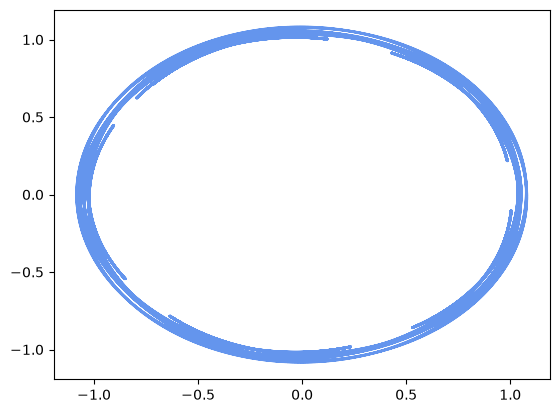

In [30]:
plt.plot(x_c_boris[0], x_c_boris[1], color = "cornflowerblue", label = "trajectory tokamak boris method")

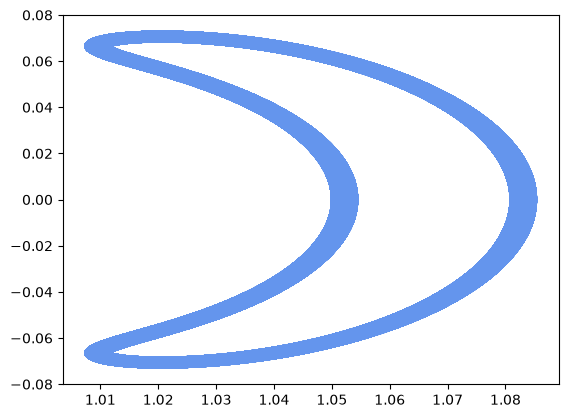

In [31]:
R_boris_C = np.sqrt(x_c_boris[0]**2 + x_c_boris[1]**2)
plt.plot(R_boris_C, x_c_boris[2], color = "cornflowerblue", label = "boris R_axis")

In [ ]:
T_c_new = 2e5
t_span_c_boris = (0,T_c_new)
t_eval_c_boris = np.linspace(0,T_c_new, n_steps_c)
initial_condition_tokamak_C = np.concatenate((x0_tokamak_C, v0_tokamak_C))




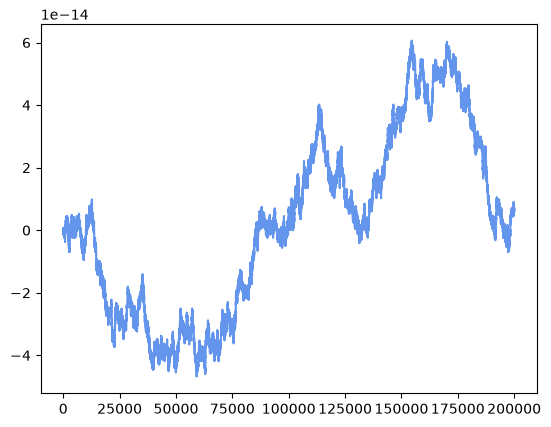

In [ ]:
H_n_tokamak_boris_C = energy(x_c_boris,v_c_boris,U_tokamak)
H0_tokomak_boris = H_n_tokamak_boris_C[0]




error_energy_tokamak_boris = (H_n_tokamak_boris_C - H0_tokomak_boris)/np.abs(H0_tokomak_boris)

plt.plot(t_eval_c_boris, error_energy_tokamak_boris, color= "cornflowerblue", label = "boris")



## Task C: Sammenligning av RK4 og Boris

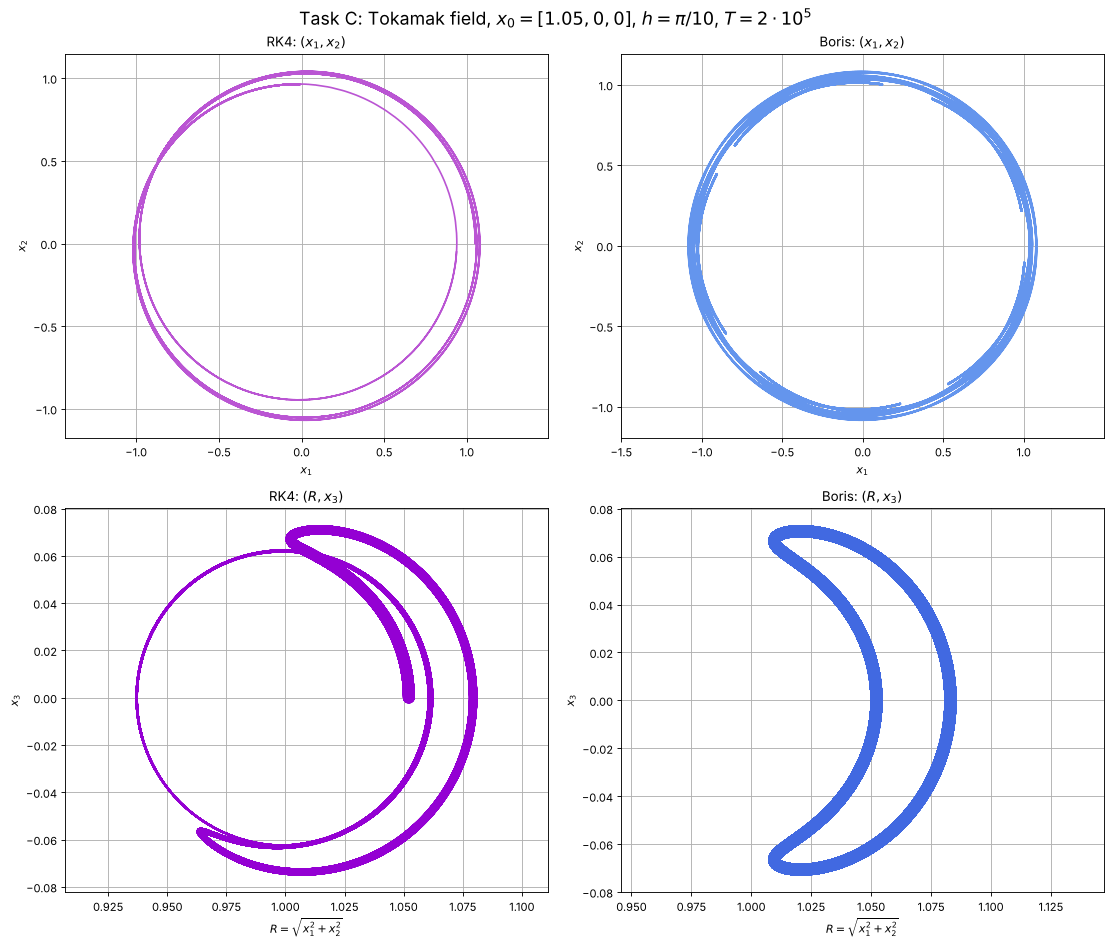

In [ ]:
# TASK C: TRAJECTORIES FOR RK4 AND BORIS SIDE BY SIDE (cf. Fig. 6 in He et al. 2015)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

#RK4, (x1, x2)-plane
axes[0, 0].plot(x_arr_tokamak_RK4_C[:, 0], x_arr_tokamak_RK4_C[:, 1], color="mediumorchid")
axes[0, 0].set_title(r"RK4: $(x_1, x_2)$")

#Boris, (x1, x2)-plane
axes[0, 1].plot(x_c_boris[0], x_c_boris[1], color="cornflowerblue")
axes[0, 1].set_title(r"Boris: $(x_1, x_2)$")

for ax in axes[0]:
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")

#RK4, (R, x3)-plane
axes[1, 0].plot(np.sqrt(x_arr_tokamak_RK4_C[:, 0]**2 + x_arr_tokamak_RK4_C[:, 1]**2), x_arr_tokamak_RK4_C[:, 2], color="darkviolet")
axes[1, 0].set_title(r"RK4: $(R, x_3)$")

#Boris, (R, x3)-plane
axes[1, 1].plot(np.sqrt(x_c_boris[0]**2 + x_c_boris[1]**2), x_c_boris[2], color="royalblue")
axes[1, 1].set_title(r"Boris: $(R, x_3)$")

for ax in axes[1]:
    ax.set_xlabel(r"$R=\sqrt{x_1^2+x_2^2}$")
    ax.set_ylabel(r"$x_3$")

for ax in axes.flat:
    ax.axis("equal")
    ax.grid(True)

fig.suptitle(r"Task C: Tokamak field, $x_0 = [1.05, 0, 0]$, $h = \pi/10$, $T = 2\cdot 10^5$", fontsize=16)
plt.tight_layout()
plt.show()


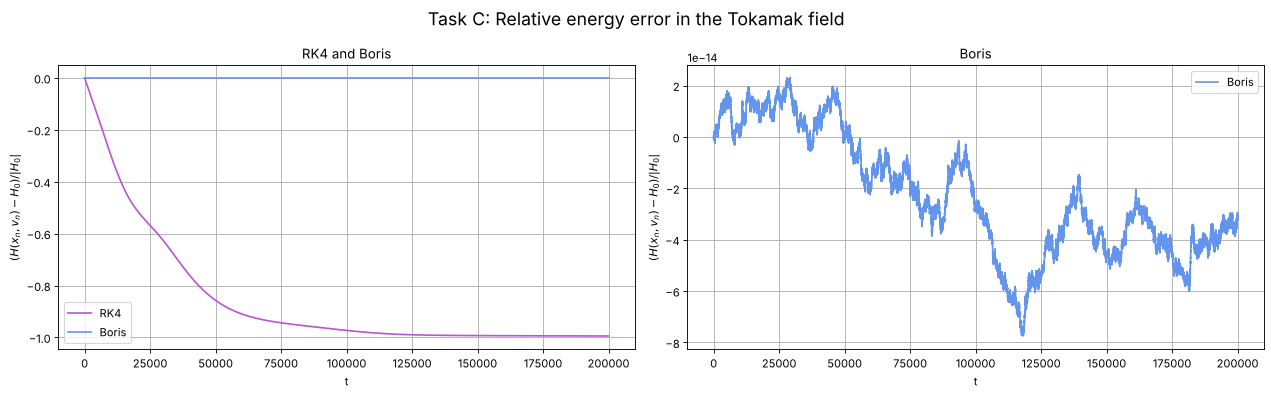

In [ ]:
# TASK C: RELATIVE ENERGY ERROR FOR RK4 AND BORIS (cf. Fig. 7 in He et al. 2015)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

#Both methods in the same plot
axes[0].plot(time_C, error_energy_tokamak, color="mediumorchid", label="RK4")
axes[0].plot(t_eval_c_boris, error_energy_tokamak_boris, color="cornflowerblue", label="Boris")
axes[0].set_title("RK4 and Boris")
axes[0].legend()

#Boris alone, so the size of the error is visible
axes[1].plot(t_eval_c_boris, error_energy_tokamak_boris, color="cornflowerblue", label="Boris")
axes[1].set_title("Boris")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("t")
    ax.set_ylabel(r"$(H(x_n, v_n) - H_0)/|H_0|$")
    ax.grid(True)

fig.suptitle("Task C: Relative energy error in the Tokamak field", fontsize=16)
plt.tight_layout()
plt.show()
